# Entrega I - Proyecto de Redes Neuronales para Datos Secuenciales
## Análisis de Sentimientos a Partir de un Dataset de Tweets Relacionados con Aerolíneas Estadounidenses

### Integrantes
| Nombre | Código |
|-----------------|--------|
| Juliana Melissa Bolaños Araujo | 2372224 |
| Lenin Esteban Carabalí Moreno | 2310025 |
| Christian David Vargas Gutiérrez| 2179172 |

Universidad del Valle  
Escuela de Ingeniería de Sistemas y Computación  
Octubre 2026

---

### Descripción

En este Notebook se desarrolla la primera entrega del proyecto práctico de la asignatura de **Redes Neuronales para Datos Secuenciales**. El objetivo es entrenar y evaluar distintas variantes de una arquitectura de **Perceptrón Multicapa (MLP)** para la clasificación de textos relacionados con aerolíneas estadounidenses. En particular, se busca predecir el sentimiento expresado por los usuarios (**negativo, neutral y positivo**) a partir de un conjunto de datos de tweets.

### Dataset

**Nombre:** Twitter US Airline Sentiment

**Fuente:** [Kaggle](https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment) 

**Clases:** positivo, negativo, neutral

**Total de Tweets:** 14,640

---

### Estructura del notebook

| Sección | Contenido |
|---------|-----------|
| 1 | Configuración del Entorno y Descarga del Dataset |
| 2 | Preprocesamiento del Dataset y Análisis Exploratorio de Datos |
| 3 | Preprocesamiento del Texto y Vectorización de Tweets |
| 4 | Entrenamiento de un Modelo de MLP con Tweets Vectorizados Mediante Multi-hot Encoding de 1-gramas |
| 5 | Entrenamiento de un modelo de MLP con Tweets Vectorizados Mediante TF-IDF de 2-gramas |
| 6 | Comparación Entre Los Modelos Entrenados |
| 7 | Despliegue de los Modelos y Pruebas Cualitativas |
| 8 | Conclusiones |

## 1. Configuración del Entorno y Descarga del Dataset

In [57]:
# Instalación de librerías necesarias
!pip install -q numpy pandas emoji matplotlib seaborn tensorflow tensorboard keras keras-tuner kagglehub scikit-learn nltk


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [58]:
# Importar librerías necesarias
import os, random, re, gc, emoji, kagglehub
from pathlib import Path
import ctypes
import tensorflow as tf
import keras, keras_tuner, nltk
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

SEED = 24
BATCH_SIZE = 32
MAX_TOKENS_EN_VOCABULARIO = 20_000
MAX_EPOCAS = 20

# Función para obtener una ruta compatible con Windows evitando errores con tildes o caracteres especiales en TensorFlow / Keras Tuner
def obtener_ruta_segura(ruta):
    p = Path(ruta).resolve()
    p.mkdir(parents=True, exist_ok=True)
    if os.name == 'nt':
        buf = ctypes.create_unicode_buffer(1024)
        if ctypes.windll.kernel32.GetShortPathNameW(str(p), buf, 1024):
            return Path(buf.value)
    return p

MODELS_DIR = obtener_ruta_segura("modelos")
RESULTADOS_TUNER_DIR = str(obtener_ruta_segura("resultados_keras_tuner"))

MORADO = "#4b006e"
AZUL = "#069af3"
VERDE = "#12e193"

In [59]:
# Descarga del dataset desde Kaggle
path_to_dataset = kagglehub.dataset_download('crowdflower/twitter-airline-sentiment')
print(f"Dataset descargado en: {path_to_dataset}\n")
print(f"Archivos en el dataset: {os.listdir(path_to_dataset)}")

Dataset descargado en: C:\Users\lenin\.cache\kagglehub\datasets\crowdflower\twitter-airline-sentiment\versions\4

Archivos en el dataset: ['database.sqlite', 'Tweets.csv']


In [60]:
# Carga del dataset en un DataFrame de Pandas
data = pd.read_csv(os.path.join(path_to_dataset, 'Tweets.csv'))

data.head(5)

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


## 2. Preprocesamiento del Dataset y Análisis Exploratorio de Datos

Empezamos por revisar las características del dataset, para entender mejor la información que contiene y cuáles son las variables relevantes para el análisis de sentimientos.

In [61]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet_created                 14640 non-null  object 
 13  t

El dataset contiene **14,640 registros y 15 columnas**. De entrada vemos que hay columnas que no son tan relevantes para el **análisis de sentimientos a partir de texto**, como lo son el ID del tweet `tweet_id`, el nombre del usuario que publicó el tweet `name`, la cantidad de retweets `retweet_count`, la fecha de publicación del tweet `tweet_created`, las coordenadas geográficas `tweet_coord`, la ubicación geográfica `tweet_location` y la zona horaria del usuario `user_timezone`. Así que procedemos a eliminar estas columnas.

In [62]:
data.drop(columns=['tweet_id', 'name', 'retweet_count', 'tweet_created', 'tweet_coord', 'tweet_location', 'user_timezone'], inplace=True)

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   airline_sentiment             14640 non-null  object 
 1   airline_sentiment_confidence  14640 non-null  float64
 2   negativereason                9178 non-null   object 
 3   negativereason_confidence     10522 non-null  float64
 4   airline                       14640 non-null  object 
 5   airline_sentiment_gold        40 non-null     object 
 6   negativereason_gold           32 non-null     object 
 7   text                          14640 non-null  object 
dtypes: float64(2), object(6)
memory usage: 915.1+ KB


De igual manera observamos que hay algunas columnas que contienen valores nulos. Vale la pena cuantificar estos valores nulos y decidir si estas columnas verdaderamente aportan información relevante para el análisis de sentimientos.

In [63]:
print("Porcentaje de valores null o NaN por columna:")

((data.isnull() | data.isna()).sum() / len(data) * 100).round(1)

Porcentaje de valores null o NaN por columna:


airline_sentiment                0.0
airline_sentiment_confidence     0.0
negativereason                  37.3
negativereason_confidence       28.1
airline                          0.0
airline_sentiment_gold          99.7
negativereason_gold             99.8
text                             0.0
dtype: float64

Las columnas `airline_sentiment_gold` y `negativereason_gold` practicamente están vacías, por lo que no aportan información relevante para el análisis. Procedemos a eliminarlas del dataset.

In [64]:
data.drop(columns=['airline_sentiment_gold', 'negativereason_gold'], inplace=True)

print("Porcentaje de valores null o NaN por columna:")
((data.isnull() | data.isna()).sum() / len(data) * 100).round(1)

Porcentaje de valores null o NaN por columna:


airline_sentiment                0.0
airline_sentiment_confidence     0.0
negativereason                  37.3
negativereason_confidence       28.1
airline                          0.0
text                             0.0
dtype: float64

Igualmente observamos que todas las celdas de la columna `text` están llenas, por lo que no hay tweets vacíos. Adicionalmente, todos los tweets tienen un sentimiento asociado y cada una de estas valoraciones tiene un valor de confianza (no hay valores nulos en las columnas `airline_sentiment` y `airline_sentiment_confidence`). También, cada tweet tiene asociada una aerolínea (no hay valores nulos en la columna `airline`).

Finalmente, observamos que hay valores nulos en la columna `negativereason`, lo cual es esperable, ya que no todos los tweets tienen un sentimiento negativo.

Además, se observa que no todas las razones negativas tienen asociado un valor de confianza, ya que los porcentajes de valores nulos en las columnas `negativereason` y `negativereason_confidence` son diferentes.

Procedemos a identificar los valores únicos presentes en cada una de las columnas seleccionadas.



In [65]:
print(data.nunique(), "\n\n")

print("Sentimientos con los que se ha clasificado cada tweet:\n"
    f"{data['airline_sentiment'].unique().tolist()}\n")

print("Razones por las cuales se clasificó un tweet como negativo:\n"
    f"{data['negativereason'].dropna().unique().tolist()}\n")

print("Aerolíneas a las que pertenecen los tweets:\n"
    f"{data['airline'].unique().tolist()}")

airline_sentiment                   3
airline_sentiment_confidence     1023
negativereason                     10
negativereason_confidence        1410
airline                             6
text                            14427
dtype: int64 


Sentimientos con los que se ha clasificado cada tweet:
['neutral', 'positive', 'negative']

Razones por las cuales se clasificó un tweet como negativo:
['Bad Flight', "Can't Tell", 'Late Flight', 'Customer Service Issue', 'Flight Booking Problems', 'Lost Luggage', 'Flight Attendant Complaints', 'Cancelled Flight', 'Damaged Luggage', 'longlines']

Aerolíneas a las que pertenecen los tweets:
['Virgin America', 'United', 'Southwest', 'Delta', 'US Airways', 'American']


Tal como se espera, hay tres sentimientos con los que se ha clasificado cada tweet: **negativo, neutral y  positivo**. Por otro lado, hay un conjunto de razones por las cuales se marcó un tweet como negativo (**10 en total**). Finalmente, los tweets pertenecen a **6 aerolíneas diferentes**.

Es llamativo que el número de `text` únicos es menor que el número de registros del dataset (14,427 vs. 14,640). Esto podría indicar que **hay tweets duplicados**, lo cual podría afectar el entrenamiento de los modelos de clasificación. Por lo tanto, identificaremos tweets duplicados, evaluaremos su situación particular (si dos o más tweets con el mismo `text` se clasifican de manera identica o diferente) y procederemos a eliminar los duplicados que sean seguros de eliminar.

In [66]:
# Identificar todos los registros cuyo texto aparece más de una vez en el dataset
tweets_con_texto_repetido = data[data["text"].duplicated(keep=False)]
print(f"Cantidad de filas con `text` repetido: {len(tweets_con_texto_repetido)}")

# Agrupar las filas que tienen el mismo texto
grupos_con_texto_repetido = tweets_con_texto_repetido.groupby("text")
print(f"Cantidad de textos repetidos: {grupos_con_texto_repetido.ngroups}\n")


tweets_con_texto_repetido[["airline_sentiment", "text"]].sort_values("text").tail(12)

Cantidad de filas con `text` repetido: 400
Cantidad de textos repetidos: 187



,airline_sentiment,text
3604,positive,@united thanks
2285,positive,@united thanks
2859,positive,@united thanks
3565,neutral,@united thanks
3131,positive,@united thnx
3657,positive,@united thnx
12163,positive,Just got off the phone @AmericanAir customer s...
12002,positive,Just got off the phone @AmericanAir customer s...
11922,negative,“@AmericanAir: @Andrew_Wasila We're sorry you ...
12083,negative,“@AmericanAir: @Andrew_Wasila We're sorry you ...


Se encontraron **400 registros** con un `text` repetido, correspondientes a **187 textos distintos**. Algunos de estos textos se repiten más de dos veces. A continuación, verificaremos si los registros con texto repetido tienen el mismo sentimiento o si hay registros con sentimientos diferentes para el mismo texto.

In [67]:
# Textos repetidos que tienen una sola clasificación de sentimiento
tweets_mismo_sentimiento = (
    tweets_con_texto_repetido.groupby("text")
    .filter(lambda grupo: grupo["airline_sentiment"].nunique() == 1)
)

print("Registros con texto repetido y mismo sentimiento:", len(tweets_mismo_sentimiento))

tweets_mismo_sentimiento[["airline_sentiment", "text"]].sort_values("text").tail(14)

Registros con texto repetido y mismo sentimiento: 343


,airline_sentiment,text
1477,positive,@united thank you!
3752,positive,@united thank you!
1170,positive,@united thank you!
1969,positive,@united thank you!
2647,positive,@united thank you.
867,positive,@united thank you.
3657,positive,@united thnx
3131,positive,@united thnx
12163,positive,Just got off the phone @AmericanAir customer s...
12002,positive,Just got off the phone @AmericanAir customer s...


In [68]:
# Textos repetidos que tienen clasificaciones de sentimiento diferentes
tweets_sentimiento_diferente = (
    tweets_con_texto_repetido.groupby("text")
    .filter(lambda grupo: grupo["airline_sentiment"].nunique() > 1)
)

print("Registros con texto repetido y sentimiento diferente:", len(tweets_sentimiento_diferente))

tweets_sentimiento_diferente[["airline_sentiment", "text"]].sort_values("text").tail(11)

Registros con texto repetido y sentimiento diferente: 57


,airline_sentiment,text
11576,neutral,@USAirways thank you
11194,positive,@USAirways thank you
10755,positive,@USAirways thank you
3333,positive,@united Thank you.
615,neutral,@united Thank you.
515,positive,@united thanks
3604,positive,@united thanks
2859,positive,@united thanks
3565,neutral,@united thanks
2285,positive,@united thanks


De los **400 registros** con `text` repetido, **343 registros** pertenecen a grupos en los que un mismo texto conserva la misma clasificación de sentimiento. Los **57 registros** restantes pertenecen a grupos en los que un mismo texto tiene clasificaciones de sentimiento diferentes.

Para resolver estas clasificaciones contradictorias, se asignará a cada texto la clasificación de sentimiento más frecuente dentro de su grupo. Si dos o más sentimientos tienen la misma frecuencia máxima, se eliminarán todos los registros asociados a ese texto, ya que no existe evidencia suficiente para elegir una clasificación y conservarlos podría introducir ruido en el entrenamiento de los modelos.

In [69]:
indices_a_imputar = []
indices_a_eliminar = []


for texto, grupo in tweets_sentimiento_diferente.groupby("text"):
    # Cuántas veces aparece cada sentimiento
    frecuencias = grupo["airline_sentiment"].value_counts()

    # Identificar el sentimiento o los sentimientos más frecuentes
    sentimientos_mas_frecuentes = frecuencias[frecuencias == frecuencias.max()]

    # Si hay un único sentimiento más frecuente, asignarlo a todo el grupo
    if len(sentimientos_mas_frecuentes) == 1:
        sentimiento_mas_frecuente = sentimientos_mas_frecuentes.index[0]
        data.loc[data["text"] == texto, "airline_sentiment"] = sentimiento_mas_frecuente
        indices_a_imputar.extend(grupo.index)

    # Si hay empate entre dos o más sentimientos, eliminar todos los registros asociados a ese texto
    else:
        indices_a_eliminar.extend(grupo.index)


# Eliminar los registros con empate
data.drop(index=indices_a_eliminar, inplace=True)

print(f"Se imputaron {len(indices_a_imputar)} registros con la clasificación de sentimiento más frecuente.")
print(f"Se eliminaron {len(indices_a_eliminar)} registros con empate en la clasificación de sentimiento.")

Se imputaron 15 registros con la clasificación de sentimiento más frecuente.
Se eliminaron 42 registros con empate en la clasificación de sentimiento.


En este caso, **15 registros** presentaron una clasificación de sentimiento mayoritaria. Por lo tanto, se les asignó dicha clasificación. Por otro lado, **42 registros** presentaron empate en sus clasificaciones de sentimiento, por lo que se eliminaron.

En total, se eliminaron **42 registros** por empate, equivalentes al **0.29 %** de los 14,640 registros originales. Su impacto sobre el tamaño total del dataset será reducido.

Finalmente, se conservará unicamente un registro por cada grupo de registros duplicados que conservan la misma clasificación de sentimiento. Es importante eliminar los registros duplicados, **ya que un mismo texto podría quedar tanto en el conjunto de entrenamiento como en el conjunto de prueba. En ese caso, el modelo sería evaluado con una entrada que ya observó durante el entrenamiento, lo cual podría sobreestimar su desempeño.**

In [70]:
data = data.drop_duplicates(subset="text", keep="first")

print(len(data))
data.nunique()

14406


airline_sentiment                   3
airline_sentiment_confidence     1016
negativereason                     10
negativereason_confidence        1403
airline                             6
text                            14406
dtype: int64

El dataset limpio final contiene **14,406 registros** únicos. Ahora procederemos a realizar un análisis exploratorio de los datos para entender mejor su composición. 

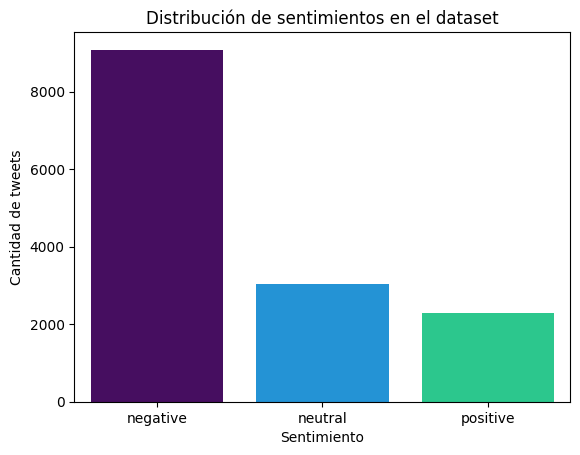

In [71]:
# Ordenar los sentimientos por cantidad de tweets, de mayor a menor
orden_sentimientos = data["airline_sentiment"].value_counts().index

sns.countplot(
    data=data,
    x="airline_sentiment",
    hue="airline_sentiment",
    order=orden_sentimientos,
    hue_order=orden_sentimientos,
    palette=[MORADO, AZUL, VERDE],
    legend=False
)

plt.xlabel("Sentimiento")
plt.ylabel("Cantidad de tweets")
plt.title("Distribución de sentimientos en el dataset")
plt.show()

Observamos que existe un desbalance importante entre las clases de sentimiento. Hay una mayor cantidad de tweets clasificados como negativos, mientras que los tweets neutrales y positivos aparecen con menor frecuencia.

Esto debe tenerse en cuenta durante el entrenamiento del modelo, ya que podría tender a clasificar una mayor cantidad de tweets como negativos por ser la clase más frecuente. Por esta razón, será importante realizar una división estratificada de los datos y penalizar al modelo por clasificar incorrectamente tweets de las clases menos frecuentes. 

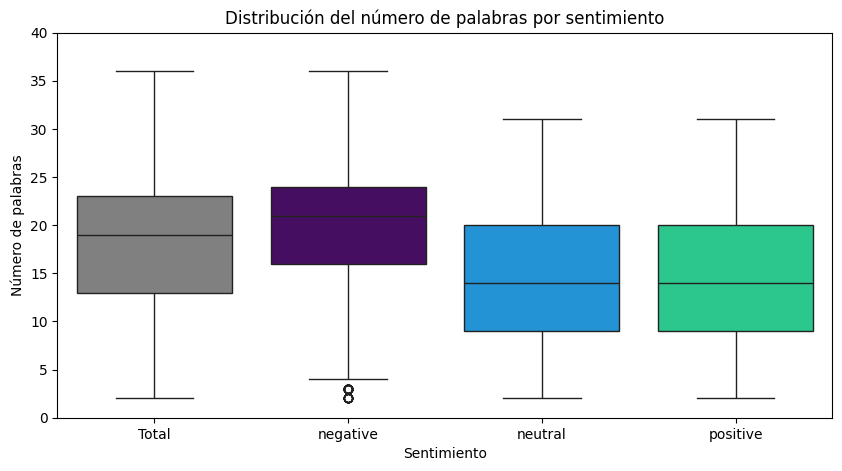

In [72]:
# Calcular el número de palabras de cada tweet
numero_palabras = data["text"].str.split().str.len()

# Crear los datos para la categoría Total y por cada sentimiento
total = pd.DataFrame({"grupo": "Total", "numero_palabras": numero_palabras})
por_sentimiento = pd.DataFrame({"grupo": data["airline_sentiment"], "numero_palabras": numero_palabras})

# Unir ambas distribuciones
datos_grafica = pd.concat([total, por_sentimiento], ignore_index=True)

orden_grupos = ["Total", "negative", "neutral", "positive"]

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=datos_grafica,
    x="grupo",
    y="numero_palabras",
    hue="grupo",
    order=orden_grupos,
    hue_order=orden_grupos,
    palette=["gray", MORADO, AZUL, VERDE],
    legend=False
)

plt.xlabel("Sentimiento")
plt.ylabel("Número de palabras")
plt.title("Distribución del número de palabras por sentimiento")

plt.ylim(0, 40)
plt.yticks(range(0, 41, 5))

plt.show()

Todos los tweets contienen al menos dos palabras y el tweet más largo tiene aproximadamente 36 palabras. En general, las longitudes de los textos de las tres clases se superponen en gran medida.

Sin embargo, los tweets negativos tienden a ser un poco más largos: su mediana se encuentra alrededor de 21 palabras, mientras que las muestras neutrales y positivas tienen una mediana cercana a 14 palabras. Aun así, la longitud de los tweets por sí sola no parece ser suficiente para determinar el sentimiento, ya que las tres distribuciones cubren un rango amplio y similar de longitudes, lo que es positivo, ya que la longitud de los tweets no debería ser un factor determinante para la clasificación de sentimientos.

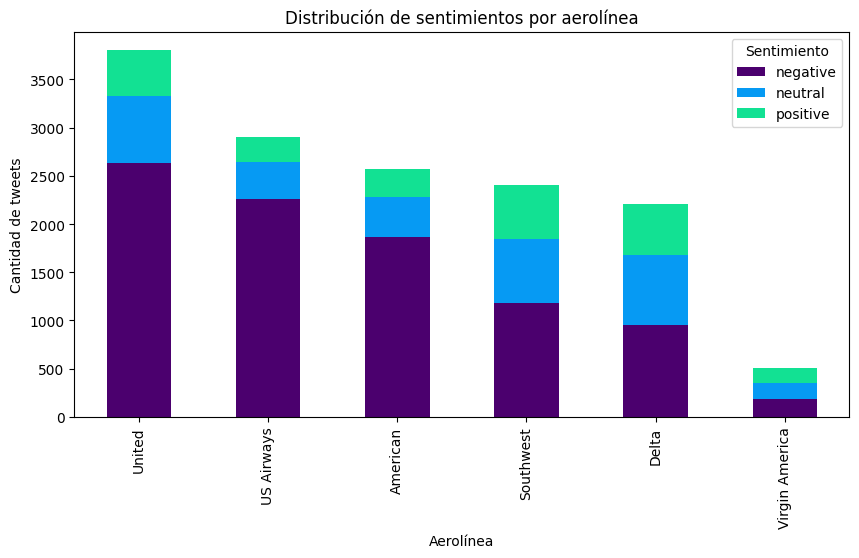

In [73]:
# Ordenar las aerolíneas por cantidad de tweets, de mayor a menor
orden_aerolineas = data["airline"].value_counts().index

# Contar los sentimientos de cada aerolínea
conteos_por_aerolinea = pd.crosstab(data["airline"], data["airline_sentiment"])
conteos_por_aerolinea = conteos_por_aerolinea.reindex(index=orden_aerolineas, columns=["negative", "neutral", "positive"])

conteos_por_aerolinea.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=[MORADO, AZUL, VERDE]
)

plt.xlabel("Aerolínea")
plt.ylabel("Cantidad de tweets")
plt.title("Distribución de sentimientos por aerolínea")
plt.legend(title="Sentimiento")

plt.show()

Observamos que también existe un desbalance en la cantidad de tweets asociados a cada aerolínea. United concentra la mayor cantidad de comentarios, mientras que Virgin America tiene la menor cantidad de muestras.

Además, las proporciones de sentimientos cambian entre aerolíneas. Por ejemplo, en US Airways predominan claramente los tweets negativos, mientras que Virgin America presenta una distribución más equilibrada entre las tres clases. Esto podría introducir un sesgo en el modelo, ya que el nombre de una aerolínea podría asociarse directamente con un sentimiento determinado.

Por esta razón, durante el preprocesamiento del texto **buscaremos eliminar las referencias a las aerolíneas, de manera que el modelo aprenda a identificar el sentimiento a partir del contenido del tweet y no de la aerolínea mencionada**.

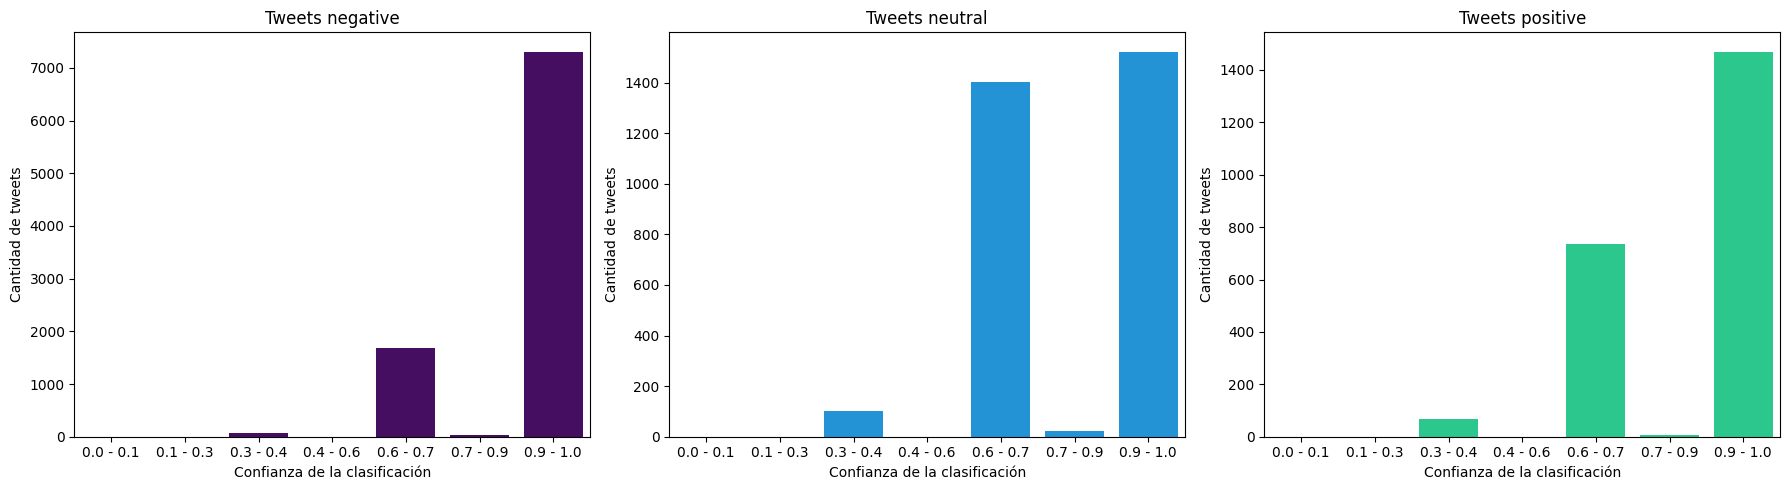

In [74]:
rangos = np.linspace(0, 1, 8)
etiquetas = [ f"{rangos[i]:.1f} - {rangos[i + 1]:.1f}" for i in range(len(rangos) - 1)]

def graficar_confianza(sentimiento, color, ax):
    # Seleccionar los tweets del sentimiento indicado
    tweets = data[data["airline_sentiment"] == sentimiento].copy()
    
    # Clasificar los valores de confianza en rangos
    tweets["rango_confianza"] = pd.cut(
        tweets["airline_sentiment_confidence"],
        bins=rangos,
        labels=etiquetas,
        include_lowest=True
    )
    
    sns.countplot(
        data=tweets,
        x="rango_confianza",
        order=etiquetas,
        color=color,
        ax=ax
    )
    
    ax.set_title(f"Tweets {sentimiento}")
    ax.set_xlabel("Confianza de la clasificación")
    ax.set_ylabel("Cantidad de tweets")


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

graficar_confianza("negative", MORADO, axes[0])
graficar_confianza("neutral", AZUL, axes[1])
graficar_confianza("positive", VERDE, axes[2])

plt.tight_layout()
plt.show()

En los tres sentimientos, la mayor cantidad de tweets se encuentra en el intervalo de confianza más alto. Esto indica que gran parte de las clasificaciones realizadas por los anotadores tiene un nivel de confianza elevado.

Sin embargo, los tweets neutrales presentan una proporción importante de observaciones en un intervalo de confianza intermedio. Esto sugiere que la clase neutral puede ser más difícil de identificar que las clases positiva y negativa, ya que algunos mensajes pueden contener expresiones ambiguas o poco claras. Sin embargo, el panorama no es crítico. 

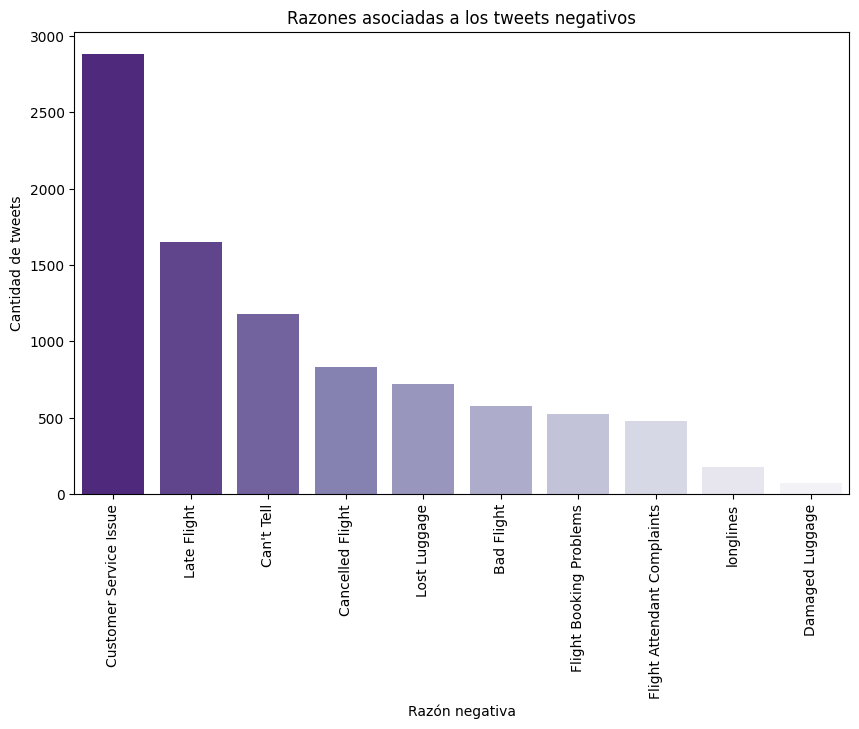

In [75]:
# Conservar únicamente los tweets clasificados como negativos
tweets_negativos = data[data["airline_sentiment"] == "negative"].copy()

# Ordenar las razones de mayor a menor frecuencia
orden_razones = (tweets_negativos["negativereason"].value_counts().index)


plt.figure(figsize=(10, 6))

sns.countplot(
    data=tweets_negativos,
    x="negativereason",
    hue="negativereason",
    order=orden_razones,
    hue_order=orden_razones,
    palette=sns.color_palette("Purples_r", n_colors=len(orden_razones)),
    legend=False
)

plt.ylabel("Cantidad de tweets")
plt.xticks(rotation=90)
plt.xlabel("Razón negativa")
plt.title("Razones asociadas a los tweets negativos")

plt.show()

La razón negativa más frecuente es `Customer Service Issue`, seguida por `Late Flight` y `Can't Tell`. Esto indica que una parte importante de los comentarios negativos del dataset está relacionada con problemas en la atención al cliente.

Por otro lado, algunas razones, como `Damaged Luggage` y `longlines`, tienen pocas muestras. Esto debe tenerse en cuenta al evaluar el modelo, ya que los casos poco representados pueden ser más difíciles de clasificar correctamente en escenarios reales.

## 3. Preprocesamiento del Texto y Vectorización de Tweets

Empezamos por dividir el dataset en conjuntos de entrenamiento, validación y prueba, procurando que la proporción de cada clase de sentimiento y de razón negativa se mantenga en cada conjunto.

In [76]:
# Combinar sentimiento y razón negativa para estratificar
estratos = (data["airline_sentiment"] + "_" + data["negativereason"].fillna("No reason"))
# print(estratos.value_counts())

# División del dataset en conjuntos de entrenamiento y test (80% - 20%)
entrenamiento, test = train_test_split(
    data,
    test_size=0.20,
    shuffle=True,
    random_state=SEED,
    stratify=estratos
)

# División del conjunto de entrenamiento en conjuntos de entrenamiento y validación (75% - 25%)
estratos_entrenamiento = (entrenamiento["airline_sentiment"] + "_" + entrenamiento["negativereason"].fillna("No reason"))
# print(estratos_entrenamiento.value_counts())

entrenamiento, validacion = train_test_split(
    entrenamiento,
    test_size=0.25,  # 0.25 * 0.8 = 0.2 del total
    shuffle=True,
    random_state=SEED,
    stratify=estratos_entrenamiento
)

print(f"Entrenamiento: {len(entrenamiento)} registros")
print(f"Validación: {len(validacion)} registros")
print(f"Prueba: {len(test)} registros")

Entrenamiento: 8643 registros
Validación: 2881 registros
Prueba: 2882 registros


Una vez divididos los datos, separamos los textos de entrada (`x`) y las etiquetas de sentimiento esperadas (`y`). Convertimos los textos a arreglos de NumPy para crear posteriormente los conjuntos de datos de TensorFlow.

Codificamos cada sentimiento como un número y finalmente, como un vector *one-hot* codificado. Esta representación permite entrenar un modelo con tres neuronas de salida, una por cada sentimiento.

Como las clases están desbalanceadas, calculamos pesos a partir del conjunto de entrenamiento. Durante el entrenamiento, estos pesos se pasarán mediante `class_weight` para asignar una mayor penalización, en el cálculo de la función de pérdida, a los errores cometidos en las clases menos frecuentes.

In [77]:
# Variables de entrada: texto de los tweets
x_train = entrenamiento["text"].to_numpy()
x_val = validacion["text"].to_numpy()
x_test = test["text"].to_numpy()

# Variables de salida: sentimiento.
codificacion_sentimiento = {"negative": 0, "neutral": 1, "positive": 2}

y_train = entrenamiento["airline_sentiment"].map(codificacion_sentimiento)
y_val = validacion["airline_sentiment"].map(codificacion_sentimiento)
y_test = test["airline_sentiment"].map(codificacion_sentimiento)

# ----------------
# Como las clases están desbalanceadas, es posible calcular un vector de pesos para compensar el desbalance de clases durante el entrenamiento del modelo.
# Estos pesos intervienen en la función de pérdida durante el entrenamiento, de manera que los errores cometidos en las clases minoritarias tengan un mayor peso que los errores cometidos en la clase mayoritaria.
clases = np.array(sorted(codificacion_sentimiento.values()))

pesos = compute_class_weight(class_weight="balanced", classes=clases, y=y_train)
pesos_clases = dict(zip(clases, pesos))

print("Pesos por clase:")
for sentimiento, clase in codificacion_sentimiento.items():
    print(f"{sentimiento}: {pesos_clases[clase]:.2f}")
# ----------------

# Finalmente, transformar las etiquetas de salida en vectores one-hot
y_train = keras.utils.to_categorical(y_train, num_classes=3)
y_val = keras.utils.to_categorical(y_val, num_classes=3)
y_test = keras.utils.to_categorical(y_test, num_classes=3)

print("\n\nEjemplo de entrada (x_train):", x_train[0])
print("Ejemplo de salida (y_train):", y_train[0])


# Transformación de los arrays de entrada en tensores de TensorFlow
train_ds = (tf.data.Dataset.
            from_tensor_slices((x_train, y_train))
            .batch(BATCH_SIZE)
            .shuffle(buffer_size=len(x_train), seed=SEED, reshuffle_each_iteration=True)
)
val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(BATCH_SIZE)
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test)).batch(BATCH_SIZE)

Pesos por clase:
negative: 0.53
neutral: 1.58
positive: 2.10


Ejemplo de entrada (x_train): @united since when did you get so good again!  4 transcontinental flights in 72h.  What a pleasure/relief you were.
Ejemplo de salida (y_train): [0. 0. 1.]


A continuación, estandarizamos los textos antes de construir el vocabulario. Aplicamos las siguientes transformaciones:

- Convertimos los textos a minúsculas.
- Eliminamos etiquetas HTML, enlaces y menciones a usuarios.
- Expandimos contracciones negativas para conservar expresiones como `not`.
- Conservamos el contenido de los hashtags, pero eliminamos el símbolo `#`.
- Eliminamos los nombres de las aerolíneas para evitar asociar directamente una aerolínea con un sentimiento.
- Eliminamos *stopwords*, excepto las negaciones `no`, `not`, `never` y `nor`.
- Eliminamos puntuación, emojis y otros caracteres especiales y normalizamos los espacios.

Definimos la función de estandarización únicamente con operaciones de texto de TensorFlow, ya que `TextVectorization` recibe tensores y puede ejecutar estas transformaciones dentro del flujo de datos de Keras.


Una posible transformación adicional sería aplicar *stemming*, una técnica que reduce palabras como `delayed`, `delays` y `delay` a una misma raíz. Sin embargo, decidimos no utilizarla en esta etapa. Definimos la función de estandarización únicamente con operaciones de texto de TensorFlow, ya que `TextVectorization` recibe tensores y puede ejecutar estas transformaciones dentro del flujo de datos de Keras. Los algoritmos de *stemming*, como Snowball o Porter, trabajan con cadenas de Python, no con strings de TensorFlow. Para utilizarlos, tendríamos que preprocesar los tweets antes de crear el `tf.data.Dataset` o incorporar una llamada a Python dentro del flujo. Esto impediría que todo el preprocesamiento se ejecute como parte del grafo de TensorFlow y limitaría las optimizaciones de paralelización que ofrecen `map(..., num_parallel_calls=tf.data.AUTOTUNE)` y `prefetch()`, propios de TensorFlow.

Por esta razón, mantenemos un flujo de preprocesamiento completamente basado en TensorFlow.

In [78]:
nltk.download('stopwords', quiet=True)

# Excluir las negaciones de las stopwords para conservarlas en los tweets, ya que podrían ser importantes para identificar el sentimiento.
# Por ejemplo, "not good" es negativo, mientras que "good" es positivo.
# Otro ejemplo, "it does not work" es negativo, mientras que "it does work" es positivo.
NEGACIONES = {"no", "not", "never", "nor"}
STOPWORDS = set(stopwords.words("english")) - NEGACIONES

PATRON_STOPWORDS = (
    r"\b(?:"
    + "|".join(re.escape(palabra) for palabra in STOPWORDS)
    + r")\b"
)
# print("STOPWORDS:", sorted(STOPWORDS))

# Tal como lo discutimos en el análisis exploratorio, el nombre de la aerolínea podría asociarse directamente con un sentimiento determinado. 
# Por esta razón, es mejor eliminar cualquier referencia a las aerolíneas durante el preprocesamiento del texto.
# Esta expresión regular identifica cualquier versión del nombre de las aerolíneas, incluyendo espacios, guiones y guiones bajos entre palabras (por ejemplo, "Virgin America", "Virgin_America", "Virgin-America").
PATRON_AEROLINEAS = (
    r"\b(?:"
    r"virgin[\s_/-]*america|"
    r"united|"
    r"southwest|"
    r"delta|"
    r"us[\s_/-]*airways|"
    r"american(?:[\s_/-]*air(?:lines)?)?"
    r")\b"
)


@keras.saving.register_keras_serializable(package="preprocesamiento_de_texto")
def estandarizar_tweets(textos):
    # Convertir todo a minúsculas
    textos = tf.strings.lower(textos)
    
    # Eliminar etiquetas HTML
    textos = tf.strings.regex_replace(textos, r"<[^>]+>", " ")
    
    # Eliminar enlaces
    textos = tf.strings.regex_replace(textos, r"https?://\S+|www\.\S+", " ")
    
    # Eliminar menciones como @united o @usuario
    textos = tf.strings.regex_replace(textos, r"@\w+", " ")
    
    # Expandir contracciones negativas 
    textos = tf.strings.regex_replace(textos, r"\b(?:can't|cant)\b", "can not")
    textos = tf.strings.regex_replace(textos, r"\b(?:won't|wont)\b", "will not")
    textos = tf.strings.regex_replace(textos, r"n't\b", " not")

    # Conservar la palabra de un hashtag, pero quitar el símbolo #
    textos = tf.strings.regex_replace(textos, r"#", "")

    # Eliminar nombres de aerolíneas
    textos = tf.strings.regex_replace(textos, PATRON_AEROLINEAS, " ")

    # Eliminar stopwords
    textos = tf.strings.regex_replace(textos, PATRON_STOPWORDS, " ")
    
    # Eliminar puntuación, apóstrofes, guiones, barras, _ y caracteres especiales
    textos = tf.strings.regex_replace(textos, r"[^a-z0-9\s]", " ")

    # Reducir varios espacios a uno
    textos = tf.strings.regex_replace(textos, r"\s+", " ")
    
    return tf.strings.strip(textos)


tweet_ejemplo_1 = x_train[24]
tweet_ejemplo_1_estandarizado = estandarizar_tweets(tweet_ejemplo_1)
print("Tweet ejemplo 1 original:", tweet_ejemplo_1)
print("Tweet ejemplo 1 estandarizado:", tweet_ejemplo_1_estandarizado.numpy().decode("utf-8"))

tweet_ejemplo_2 = x_train[5586]
tweet_ejemplo_2_estandarizado = estandarizar_tweets(tweet_ejemplo_2)
print("\n\nTweet ejemplo 2 original:", tweet_ejemplo_2)
print("Tweet ejemplo 2 estandarizado:", tweet_ejemplo_2_estandarizado.numpy().decode("utf-8"))

Tweet ejemplo 1 original: @SouthwestAir it's the poor customer service that I have a problem with!!!!!
Tweet ejemplo 1 estandarizado: poor customer service problem


Tweet ejemplo 2 original: @JetBlue  hahah 😂👌👌👌 love flying jet blue tho!! http://t.co/7VeE44MACM
Tweet ejemplo 2 estandarizado: hahah love flying jet blue tho


Definimos dos representaciones vectoriales a partir de los textos del conjunto de entrenamiento.

- La primera utiliza **unigramas con codificación *multi-hot***. Cada posición del vector representa una palabra del vocabulario y toma el valor `1` si la palabra aparece en el tweet. Esta representación no conserva el orden ni la cantidad de veces que aparece cada palabra. El vocabulario obtenido contiene cerca de 9,800 tokens, por lo que no alcanza el límite definido de 20,000.

- La segunda utiliza **unigramas y bigramas con ponderación TF-IDF**. Además de las palabras individuales, incorpora pares de palabras consecutivas y asigna mayor peso a los términos que son poco frecuentes en el conjunto de entrenamiento. En este caso, el vocabulario alcanza el límite de 20,000 tokens.

Finalmente, aplicamos cada vectorizador a los lotes de TensorFlow mediante `map()`. El uso de `AUTOTUNE` y `prefetch()` permite preparar los siguientes lotes mientras el modelo procesa el lote actual (lo que mejora el rendimiento del entrenamiento por el uso del paralelismo).

In [79]:
# Definición del vectorizador de 1-gramas con multi-hot encoding
vectorizador_multi_hot = keras.layers.TextVectorization(
    max_tokens=MAX_TOKENS_EN_VOCABULARIO,
    standardize=estandarizar_tweets,
    split="whitespace",
    output_mode="multi_hot"
)

# Obtención del vocabulario del vectorizador multi-hot, a partir de los tokenes de los tweets del conjunto de entrenamiento
vectorizador_multi_hot.adapt(x_train)

print("Algunos tokens del vocabulario obtenido con el vectorizador multi-hot:\n", vectorizador_multi_hot.get_vocabulary()[:20])
print("Cantidad de tokens en el vocabulario del vectorizador multi-hot:", len(vectorizador_multi_hot.get_vocabulary()))


# Ejemplo de cómo se vectoriza un tweet de ejemplo utilizando el vectorizador multi-hot
ejemplo_vectorizado_multi_hot = vectorizador_multi_hot(tf.constant([tweet_ejemplo_1])).numpy()[0]
indices_activos = np.flatnonzero(ejemplo_vectorizado_multi_hot)

print("\n\nTweet ejemplo 1 original:", tweet_ejemplo_1)
print("Tweet ejemplo 1 estandarizado:", tweet_ejemplo_1_estandarizado.numpy().decode("utf-8"))
print("Tweet ejemplo 1 vectorizado (multi-hot):", ejemplo_vectorizado_multi_hot, "Longitud del vector:", len(ejemplo_vectorizado_multi_hot))
print("Índices activos en el vector multi-hot:", indices_activos)
print("Tokens activos en el tweet ejemplo 1:", [vectorizador_multi_hot.get_vocabulary()[i] for i in indices_activos])


# Preprocesar todo el dataset con la capa de vectorización multi-hot
# Esta aproximación permite utilizar procesamiento paralelo y prefetching para mejorar el rendimiento
multi_hot_1gramas_train = train_ds.map(lambda textos, sentimientos: (vectorizador_multi_hot(textos), sentimientos),
                                       num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

multi_hot_1gramas_val = val_ds.map(lambda textos, sentimientos: (vectorizador_multi_hot(textos), sentimientos),
                                   num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

multi_hot_1gramas_test = test_ds.map(lambda textos, sentimientos: (vectorizador_multi_hot(textos), sentimientos),
                                    num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

Algunos tokens del vocabulario obtenido con el vectorizador multi-hot:
 ['[UNK]', np.str_('flight'), np.str_('not'), np.str_('no'), np.str_('get'), np.str_('thanks'), np.str_('cancelled'), np.str_('service'), np.str_('help'), np.str_('2'), np.str_('time'), np.str_('customer'), np.str_('hours'), np.str_('flights'), np.str_('amp'), np.str_('hold'), np.str_('us'), np.str_('would'), np.str_('plane'), np.str_('still')]
Cantidad de tokens en el vocabulario del vectorizador multi-hot: 9791


Tweet ejemplo 1 original: @SouthwestAir it's the poor customer service that I have a problem with!!!!!
Tweet ejemplo 1 estandarizado: poor customer service problem
Tweet ejemplo 1 vectorizado (multi-hot): [0 0 0 ... 0 0 0] Longitud del vector: 9791
Índices activos en el vector multi-hot: [  7  11 217 259]
Tokens activos en el tweet ejemplo 1: [np.str_('service'), np.str_('customer'), np.str_('problem'), np.str_('poor')]


In [80]:
# Definición del vectorizador de 2-gramas con TF-IDF
vectorizador_2gram_tf_idf = keras.layers.TextVectorization(
    ngrams = 2,
    max_tokens=MAX_TOKENS_EN_VOCABULARIO,
    standardize=estandarizar_tweets,
    split="whitespace",
    output_mode="tf_idf"
)

# Obtención del vocabulario del vectorizador 2-gramas TF-IDF, a partir de los tokenes de los tweets del conjunto de entrenamiento
vectorizador_2gram_tf_idf.adapt(x_train)

print("Algunos tokens del vocabulario obtenido con el vectorizador 2-gramas TF-IDF:\n", vectorizador_2gram_tf_idf.get_vocabulary()[-20:])
print("Cantidad de tokens en el vocabulario del vectorizador 2-gramas TF-IDF:", len(vectorizador_2gram_tf_idf.get_vocabulary()))


# Ejemplo de cómo se vectoriza un tweet de ejemplo utilizando el vectorizador tf-idf de 2-gramas
ejemplo_vectorizado_2gram_tf_idf = vectorizador_2gram_tf_idf(tf.constant([tweet_ejemplo_2])).numpy()[0]
indices_activos_2gram = np.flatnonzero(ejemplo_vectorizado_2gram_tf_idf)

print("\n\nTweet ejemplo 2 original:", tweet_ejemplo_2)
print("Tweet ejemplo 2 estandarizado:", tweet_ejemplo_2_estandarizado.numpy().decode("utf-8"))
print("Tweet ejemplo 2 vectorizado (2-gramas TF-IDF):", ejemplo_vectorizado_2gram_tf_idf, "Longitud del vector:", len(ejemplo_vectorizado_2gram_tf_idf))
print("Índices activos en el vector 2-gramas TF-IDF:", indices_activos_2gram)
print("Tokens activos en el tweet ejemplo 2:", [vectorizador_2gram_tf_idf.get_vocabulary()[i] for i in indices_activos_2gram])


# Preprocesar todo el dataset con la capa de vectorización 2-gramas TF-IDF
# Esta aproximación permite utilizar procesamiento paralelo y prefetching para mejorar el rendimiento
tf_idf_2gramas_train = train_ds.map(lambda textos, sentimientos: (vectorizador_2gram_tf_idf(textos), sentimientos),
                                     num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

tf_idf_2gramas_val = val_ds.map(lambda textos, sentimientos: (vectorizador_2gram_tf_idf(textos), sentimientos),
                                   num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

tf_idf_2gramas_test = test_ds.map(lambda textos, sentimientos: (vectorizador_2gram_tf_idf(textos), sentimientos),
                                    num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

Algunos tokens del vocabulario obtenido con el vectorizador 2-gramas TF-IDF:
 [np.str_('stopped giving'), np.str_('stopped due'), np.str_('stopped allowing'), np.str_('stopover'), np.str_('stop yelling'), np.str_('stop way'), np.str_('stop understaffing'), np.str_('stop trying'), np.str_('stop told'), np.str_('stop spending'), np.str_('stop shit'), np.str_('stop serving'), np.str_('stop service'), np.str_('stop san'), np.str_('stop reposting'), np.str_('stop relationship'), np.str_('stop portland'), np.str_('stop please'), np.str_('stop overheating'), np.str_('stop no')]
Cantidad de tokens en el vocabulario del vectorizador 2-gramas TF-IDF: 20000


Tweet ejemplo 2 original: @JetBlue  hahah 😂👌👌👌 love flying jet blue tho!! http://t.co/7VeE44MACM
Tweet ejemplo 2 estandarizado: hahah love flying jet blue tho
Tweet ejemplo 2 vectorizado (2-gramas TF-IDF): [31.407589  0.        0.       ...  0.        0.        0.      ] Longitud del vector: 20000
Índices activos en el vector 2-gramas TF-IDF

Con esto, ya contaríamos con dos representaciones vectoriales distintas: una mediante unigramas con codificación *multi-hot* y otra mediante unigramas y bigramas con TF-IDF. A continuación, definiremos y entrenaremos modelos de clasificación utilizando estas dos representaciones, para comparar su desempeño y determinar cuál es la más adecuada para el análisis que buscamos realizar.

## 4. Entrenamiento de un Modelo de MLP con Tweets Vectorizados Mediante Multi-hot Encoding de 1-gramas

En este primer modelo, utilizaremos la vectorización definida mediante **multi-hot encoding de 1-gramas** con la función `vectorizador_multi_hot()`.

Para escoger los hiperparámetros del modelo utilizaremos la librería `Keras Tuner`. Los hiperparámetros son decisiones que se definen antes del entrenamiento, como la cantidad de capas, el número de neuronas, la tasa de *dropout* y la tasa de aprendizaje.

Utilizaremos la clase `Hyperband`, que genera y evalúa distintas configuraciones del modelo a partir del desempeño sobre el conjunto de validación. Este método descarta temprano las configuraciones con peores resultados y asigna más épocas de entrenamiento a las alternativas más prometedoras, lo que permite realizar la búsqueda de forma más eficiente.

En particular, evaluaremos combinaciones de los siguientes hiperparámetros:

- Entre 1, 2, 3 o 4 capas ocultas.
- Entre 16, 32, 64, 128 o 256 neuronas por capa.
- Tasa de regularización L2 de 0.0, 0.01, 0.001 o 0.0001.
- Tasas de *dropout* de 0.20, 0.35 o 0.50 en cada capa.
- Tasas de aprendizaje de 0.01, 0.001 o 0.0001.

A partir de esta búsqueda, seleccionaremos la configuración con mejor desempeño en el conjunto de validación.

In [81]:
DIMENSION_ENTRADA_MULTI_HOT = len(vectorizador_multi_hot.get_vocabulary())

# Definición del modelo de red neuronal multicapa (MLP) con hiperparámetros ajustables mediante Keras Tuner
def crear_modelo_multi_hot(hp):
    modelo = keras.Sequential(name="mlp_multi_hot")

    modelo.add(keras.Input(shape=(DIMENSION_ENTRADA_MULTI_HOT,)))

    num_capas_ocultas = hp.Choice("num_capas_ocultas", values=[1, 2, 3, 4])

    regularizacion_l2 = hp.Choice("regularizacion_l2", values=[0.0, 0.01, 0.001, 0.0001])

    for indice_capa in range(num_capas_ocultas):
        neuronas = hp.Choice(f"neuronas_capa{indice_capa + 1}", values=[16, 32, 64, 128, 256])
        dropout = hp.Choice(f"dropout_capa{indice_capa + 1}", values=[0.20, 0.35, 0.50])

        modelo.add(keras.layers.Dense(neuronas, activation="relu",
                                      kernel_regularizer=keras.regularizers.l2(regularizacion_l2)))
        modelo.add(keras.layers.Dropout(dropout))

    modelo.add(keras.layers.Dense(3, activation="softmax"))

    tasa_aprendizaje = hp.Choice("tasa_aprendizaje", values=[0.01, 0.001, 0.0001])

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=tasa_aprendizaje),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return modelo

Una vez definida la función que construye el modelo y sus hiperparámetros ajustables, creamos una instancia de `Hyperband` para explorar las distintas configuraciones posibles.

Antes de iniciar el entrenamiento, utilizamos `search_space_summary()` para verificar el espacio de búsqueda definido. De esta forma, podemos confirmar las alternativas disponibles para la cantidad de capas ocultas, neuronas, tasas de *dropout*, regularización L2 y tasa de aprendizaje.

El criterio de selección será la menor pérdida sobre el conjunto de validación (`val_loss`). Hyperband entrenará inicialmente varias configuraciones durante pocas épocas y asignará más recursos a aquellas que obtengan mejores resultados.

In [82]:
# Establecer el espacio de búsqueda de hiperparámetros para el modelo MLP con vectorización multi-hot, utilizando Keras Tuner con el algoritmo Hyperband
tuner_multi_hot = keras_tuner.Hyperband(
    hypermodel=crear_modelo_multi_hot,
    objective=keras_tuner.Objective("val_loss", direction="min"),
    max_epochs=MAX_EPOCAS,
    factor=3,
    hyperband_iterations=1,
    directory=RESULTADOS_TUNER_DIR,
    project_name="mlp_multi_hot_1gramas",
    overwrite=True,
    seed=SEED
)

print("Espacio de búsqueda de hiperparámetros para el modelo MLP con vectorización multi-hot:\n")
tuner_multi_hot.search_space_summary()

Espacio de búsqueda de hiperparámetros para el modelo MLP con vectorización multi-hot:

Search space summary
Default search space size: 5
num_capas_ocultas (Choice)
{'default': 1, 'conditions': [], 'values': [1, 2, 3, 4], 'ordered': True}
regularizacion_l2 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.01, 0.001, 0.0001], 'ordered': True}
neuronas_capa1 (Choice)
{'default': 16, 'conditions': [], 'values': [16, 32, 64, 128, 256], 'ordered': True}
dropout_capa1 (Choice)
{'default': 0.2, 'conditions': [], 'values': [0.2, 0.35, 0.5], 'ordered': True}
tasa_aprendizaje (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


A continuación, `Keras Tuner` realizará la búsqueda sobre el espacio de hiperparámetros definido previamente. Cada configuración se evaluará sobre el conjunto de validación y se seleccionará aquella que alcance la menor pérdida de validación (`val_loss`).

Durante la búsqueda, utilizamos los pesos de clase calculados a partir del conjunto de entrenamiento para compensar el desbalance entre los sentimientos.

In [83]:
# Este callback detiene el entrenamiento si la métrica de validación no mejora durante 3 épocas consecutivas, y restaura los pesos del modelo a los de la mejor época.
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Se ejecuta la búsqueda de mejores hiperparámetros.
tuner_multi_hot.search(
    multi_hot_1gramas_train,
    validation_data=multi_hot_1gramas_val,
    epochs=MAX_EPOCAS,
    class_weight=pesos_clases,
    callbacks=[early_stopping],
    verbose=1
)

Trial 30 Complete [00h 00m 34s]
val_loss: 1.3926149606704712

Best val_loss So Far: 0.5494004487991333
Total elapsed time: 00h 05m 30s


Obtenemos e imprimimos la configuración de hiperparámetros que alcanzó la menor pérdida sobre el conjunto de validación.

In [84]:
mejor_hp_multi_hot = tuner_multi_hot.get_best_hyperparameters(num_trials=1)[0]

print("Mejores hiperparámetros encontrados:")

print(f"Numero de capas: {mejor_hp_multi_hot.get('num_capas_ocultas')}")
print(f"Regularización L2: {mejor_hp_multi_hot.get('regularizacion_l2')}")
print(f"Learning rate: {mejor_hp_multi_hot.get('tasa_aprendizaje')}")

for i in range(mejor_hp_multi_hot.get("num_capas_ocultas")):
    neuronas = mejor_hp_multi_hot.get(f'neuronas_capa{i + 1}')
    dropout = mejor_hp_multi_hot.get(f'dropout_capa{i + 1}')
    print(f"Capa oculta {i + 1} -> Neuronas: {neuronas} | Dropout: {dropout}")

Mejores hiperparámetros encontrados:
Numero de capas: 2
Regularización L2: 0.0
Learning rate: 0.0001
Capa oculta 1 -> Neuronas: 256 | Dropout: 0.5
Capa oculta 2 -> Neuronas: 16 | Dropout: 0.35


### 4.2. Visibilidad del Proceso de Experimentación y Progresión de Hiperparámetros

Para analizar cómo `Hyperband` exploró el espacio de búsqueda de hiperparámetros del modelo MLP con codificación *multi-hot*, recopilamos los ensayos (*trials*) registrados durante el proceso de optimización.

A partir de estos ensayos, identificamos las arquitecturas evaluadas y sus valores de pérdida de validación (`val_loss`). Esto permite comparar las configuraciones con mejores y peores resultados, considerando aspectos como la cantidad de capas ocultas, el número de neuronas, la tasa de aprendizaje y la regularización.

In [85]:
# Función para extraer y tabular la progresión de ensayos del Tuner
def obtener_tabla_trials(tuner):
    filas = []
    for trial in tuner.oracle.trials.values():
        if trial.status == 'COMPLETED' and trial.score is not None:
            hp = trial.hyperparameters.values
            num_capas = hp.get('num_capas_ocultas', 1)
            arquit = ' -> '.join([str(hp.get(f'neuronas_capa{i+1}', '')) for i in range(num_capas)])
            filas.append({
                'Trial': trial.trial_id,
                'val_loss': round(float(trial.score), 4),
                'Capas': num_capas,
                'Arquitectura': arquit,
                'L2': hp.get('regularizacion_l2'),
                'LR': hp.get('tasa_aprendizaje'),
                'Dropout C1': hp.get('dropout_capa1'),
            })
    return pd.DataFrame(filas).sort_values('val_loss').reset_index(drop=True)

df_trials_multi_hot = obtener_tabla_trials(tuner_multi_hot)
print(f"Total de ensayos completados: {len(df_trials_multi_hot)} | Mejor val_loss: {df_trials_multi_hot['val_loss'].min():.4f} | Peor val_loss: {df_trials_multi_hot['val_loss'].max():.4f}\n")
df_trials_multi_hot.head(10)

Total de ensayos completados: 30 | Mejor val_loss: 0.5494 | Peor val_loss: 1.4207



,Trial,val_loss,Capas,Arquitectura,L2,LR,Dropout C1
0,0024,0.5494,2,256 -> 16,0.0000,0.0001,0.50
1,0014,0.5540,3,64 -> 256 -> 16,0.0000,0.0001,0.20
2,0016,0.5607,3,64 -> 256 -> 16,0.0000,0.0001,0.20
3,0021,0.5707,2,256 -> 16,0.0000,0.0001,0.50
4,0025,0.5840,4,64 -> 128 -> 16 -> 16,0.0000,0.0010,0.35
5,0019,0.5885,4,64 -> 128 -> 16 -> 16,0.0000,0.0010,0.35
6,0002,0.6091,3,64 -> 16 -> 32,0.0000,0.0010,0.35
7,0023,0.6350,3,32 -> 128 -> 32,0.0000,0.0100,0.20
8,0028,0.6579,3,32 -> 32 -> 128,0.0001,0.0010,0.50
9,0017,0.6588,3,16 -> 64 -> 32,0.0010,0.0010,0.20


In [86]:
configuraciones = set()

for trial in tuner_multi_hot.oracle.trials.values():
    hp = trial.hyperparameters.values
    n = hp["num_capas_ocultas"]

    config = (
        n,
        hp["regularizacion_l2"],
        hp["tasa_aprendizaje"],
        tuple(
            (
                hp[f"neuronas_capa{i+1}"],
                hp[f"dropout_capa{i+1}"]
            )
            for i in range(n)
        )
    )

    configuraciones.add(config)

print("Trials registrados:", len(tuner_multi_hot.oracle.trials))
print("Configuraciones distintas:", len(configuraciones))

Trials registrados: 30
Configuraciones distintas: 22


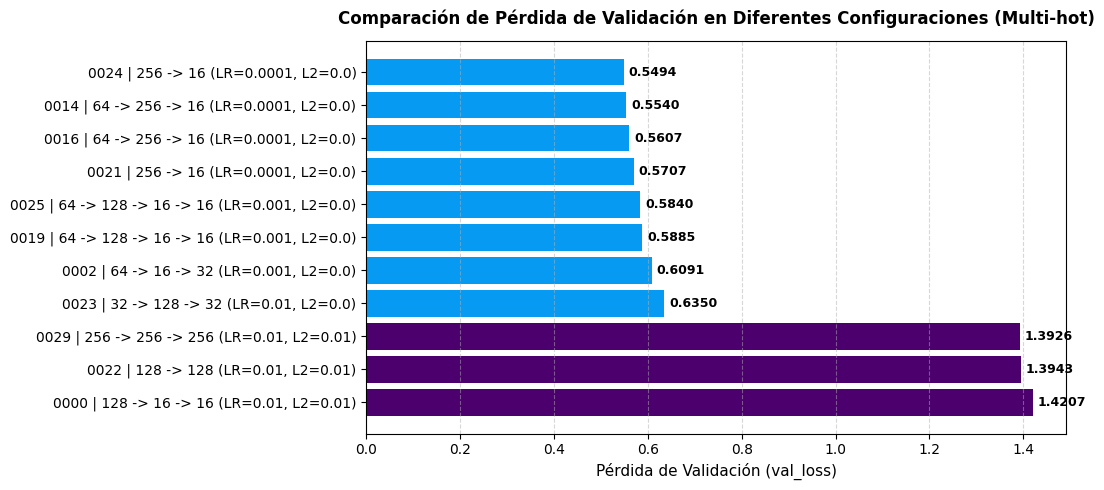

In [87]:
# Gráfica de comparación de configuraciones evaluadas durante la búsqueda
def graficar_comparacion_hiperparametros(df_trials, titulo, top_n=8, peor_n=3):
    df_sub = pd.concat([df_trials.head(top_n), df_trials.tail(peor_n)]).copy()
    df_sub['Etiqueta'] = df_sub['Trial'] + ' | ' + df_sub['Arquitectura'] + ' (LR=' + df_sub['LR'].astype(str) + ', L2=' + df_sub['L2'].astype(str) + ')'
    
    plt.figure(figsize=(11, 5))
    colores = [AZUL if i < top_n else MORADO for i in range(len(df_sub))]
    barras = plt.barh(df_sub['Etiqueta'], df_sub['val_loss'], color=colores)
    plt.gca().invert_yaxis()
    plt.xlabel('Pérdida de Validación (val_loss)', fontsize=11)
    plt.title(titulo, fontsize=12, fontweight='bold', pad=12)
    plt.grid(axis='x', linestyle='--', alpha=0.5)
    
    for bar in barras:
        ancho = bar.get_width()
        plt.text(ancho + 0.01, bar.get_y() + bar.get_height() / 2, f'{ancho:.4f}',
                 va='center', ha='left', fontsize=9, fontweight='bold')
    
    plt.tight_layout()
    plt.show()

graficar_comparacion_hiperparametros(df_trials_multi_hot, 'Comparación de Pérdida de Validación en Diferentes Configuraciones (Multi-hot)')

#### Análisis del Proceso de Experimentación y Progresión (Multi-hot):

1. **Sensibilidad a la Tasa de Aprendizaje (*Learning Rate*):** Los mejores ensayos se concentraron de manera consistente en tasas de aprendizaje moderadas/bajas ($\eta = 0.0001$). Valores más agresivos ($\eta = 0.01$) generaron pérdidas de validación significativamente superiores ($> 1.20$).
2. **Impacto de la Regularización (L2 y Dropout):** La configuración óptima prescinde de regularización L2 (`0.0`) y delega el control del sobreajuste a tasas de *dropout* balanceadas ($0.50$ y $0.35$).
3. **Profundidad de la Red:** Las arquitecturas de 2 capas ocultas ($256 \rightarrow 16$) lograron un compromiso ideal entre expresividad y generalización sin incurrir en sobreajuste severo.

Ahora construimos el modelo que vamos a entrenar, utilizando los mejores hiperparámetros encontrados en la búsqueda.

In [88]:
keras.backend.clear_session()
gc.collect()

mlp_multi_hot = tuner_multi_hot.hypermodel.build(mejor_hp_multi_hot)
mlp_multi_hot.summary()

Model: "mlp_multi_hot"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     2,506,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         4,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,510,915 (9.58 MB)

 Trainable params: 2,510,915 (9.58 MB)

 Non-trainable params: 0 (0.00 B)

Con los mejores hiperparámetros encontrados, entrenamos nuevamente el modelo desde cero sobre el conjunto de entrenamiento.

In [89]:
# Este Callback detiene el entrenamiento si la métrica de validación no mejora durante 5 épocas consecutivas, y restaura los pesos del modelo a los de la mejor época.
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Este Callback guarda el modelo en el directorio `modelos` cada vez que la métrica de validación mejora, de manera que al finalizar el entrenamiento se tendrá guardado el modelo con mejor desempeño en validación.
model_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(MODELS_DIR / "mlp_multi_hot_mejor.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Entrenamiento del modelo MLP con vectorización multi-hot, utilizando los mejores hiperparámetros encontrados por Keras Tuner,
# los pesos de clase para compensar el desbalance de clases, y los callbacks de early stopping y model checkpoint.
historial_mlp_multi_hot = mlp_multi_hot.fit(
    multi_hot_1gramas_train,
    validation_data=multi_hot_1gramas_val,
    epochs=MAX_EPOCAS,
    class_weight=pesos_clases,
    callbacks=[early_stopping, model_checkpoint],
    verbose=1
)

epoca_mejor = early_stopping.best_epoch + 1

Epoch 1/20


c:\Users\lenin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


271/271 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5881 - loss: 1.0741
Epoch 1: val_loss improved from None to 0.98415, saving model to C:\Users\lenin\DOCUME~1\INGENI~1\2026-2\RN\REDES-~1\modelos\mlp_multi_hot_mejor.keras

Epoch 1: finished saving model to C:\Users\lenin\DOCUME~1\INGENI~1\2026-2\RN\REDES-~1\modelos\mlp_multi_hot_mejor.keras
271/271 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step - accuracy: 0.5881 - loss: 1.0741 - val_accuracy: 0.7254 - val_loss: 0.9841
Epoch 2/20
271/271 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6899 - loss: 0.9841
Epoch 2: val_loss improved from 0.98415 to 0.83460, saving model to C:\Users\lenin\DOCUME~1\INGENI~1\2026-2\RN\REDES-~1\modelos\mlp_multi_hot_mejor.keras

Epoch 2: finished saving model to C:\Users\lenin\DOCUME~1\INGENI~1\2026-2\RN\REDES-~1\modelos\mlp_multi_hot_mejor.keras
271/271 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.6899 - loss: 0.9841 - val_accuracy: 0.7359 - val_loss: 0.8346
Epoch 3/20
270/271 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step -

Para analizar el comportamiento del modelo durante el entrenamiento, definimos una función que grafica en paralelo la pérdida y la exactitud sobre los conjuntos de entrenamiento y validación, además de una función que genere la matriz de confusión y el reporte de clasificación sobre el conjunto de prueba.

In [90]:
# Gráficas de pérdida y exactitud durante el entrenamiento
def graficar_historial(historial, titulo, epoca_mejor=None):
    epocas = range(1, len(historial.history["loss"]) + 1)

    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

    ejes[0].plot(epocas, historial.history["loss"], label="Entrenamiento")
    ejes[0].plot(epocas, historial.history["val_loss"], label="Validación")

    ejes[1].plot(epocas, historial.history["accuracy"], label="Entrenamiento")
    ejes[1].plot(epocas, historial.history["val_accuracy"], label="Validación")

    for eje in ejes:
        if epoca_mejor is not None:
            eje.axvline(epoca_mejor, color="green", linestyle="--", label="Early Stopping")
        
        eje.set_xlabel("Época")
        eje.legend()

    ejes[0].set_title("Pérdida")
    ejes[0].set_ylabel("Pérdida")

    ejes[1].set_title("Exactitud")
    ejes[1].set_ylabel("Exactitud")

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


# Matriz de confusión sobre los datos de test
def generar_matriz_confusion(y_test_real, y_test_predicho, nombres_sentimientos, titulo):
    matriz_confusion = confusion_matrix(y_test_real, y_test_predicho)

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        matriz_confusion,
        annot=True,
        fmt="d",
        cmap="Purples",
        xticklabels=nombres_sentimientos,
        yticklabels=nombres_sentimientos
    )

    plt.xlabel("Sentimiento predicho")
    plt.ylabel("Sentimiento real")
    plt.title(titulo)

    plt.show()


# Generación de puntajes de precisión, recall y F1-score sobre los datos de test
def generar_reporte_clasificacion(y_test_real, y_test_predicho, nombres_sentimientos):
    reporte = classification_report(
        y_test_real,
        y_test_predicho,
        target_names=nombres_sentimientos,
        output_dict=True
    )
    df_reporte = pd.DataFrame(reporte).transpose()
    df_reporte = df_reporte.round(3)

    print("Reporte de clasificación:\n")
    print(df_reporte)


Finalmente, visualizamos el historial de entrenamiento y evaluamos el modelo sobre el conjunto de prueba. Este conjunto no se utilizó durante el entrenamiento ni durante la selección de hiperparámetros, por lo que permite estimar el desempeño final del modelo sobre datos no vistos.

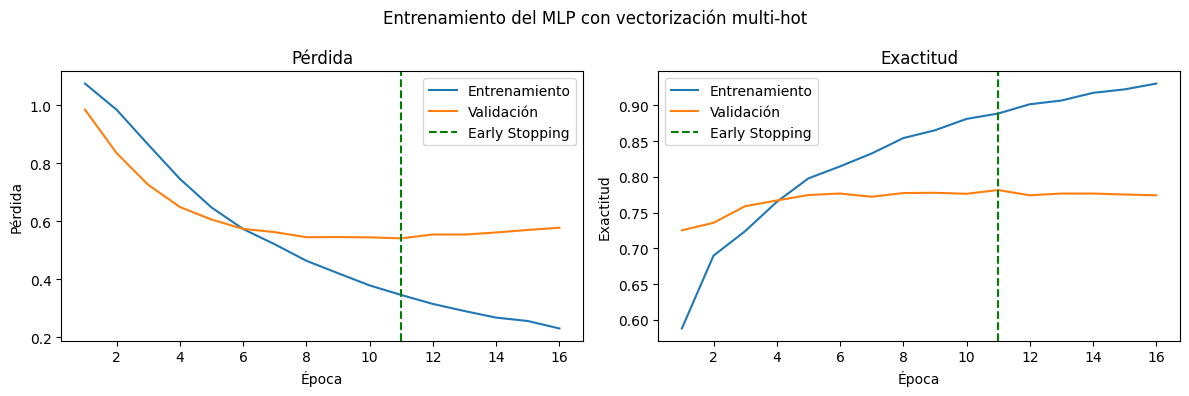

Métricas en el conjunto de prueba:
accuracy: 0.7866
loss: 0.5401


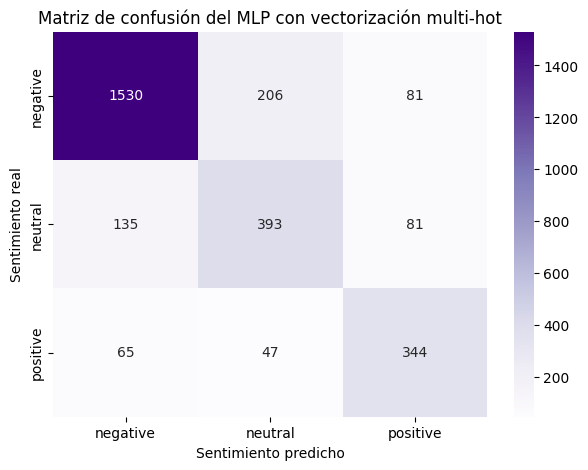

Reporte de clasificación:

              precision  recall  f1-score   support
negative          0.884   0.842     0.863  1817.000
neutral           0.608   0.645     0.626   609.000
positive          0.680   0.754     0.715   456.000
accuracy          0.787   0.787     0.787     0.787
macro avg         0.724   0.747     0.735  2882.000
weighted avg      0.794   0.787     0.789  2882.000


In [91]:
graficar_historial(historial_mlp_multi_hot, "Entrenamiento del MLP con vectorización multi-hot", epoca_mejor=epoca_mejor)

metricas_test = mlp_multi_hot.evaluate(multi_hot_1gramas_test, return_dict=True, verbose=0)

print("Métricas en el conjunto de prueba:")
for metrica, valor in metricas_test.items():
    print(f"{metrica}: {valor:.4f}")


y_test_real = y_test.argmax(axis=1)
y_test_predicho = mlp_multi_hot.predict(multi_hot_1gramas_test, verbose=0).argmax(axis=1)
nombres_sentimientos = list(codificacion_sentimiento.keys())

generar_matriz_confusion(y_test_real, y_test_predicho, nombres_sentimientos, "Matriz de confusión del MLP con vectorización multi-hot")
generar_reporte_clasificacion(y_test_real, y_test_predicho, nombres_sentimientos)

El modelo alcanza una exactitud de **78.7 %** sobre el conjunto de prueba y una pérdida de **0.549**. La gráfica de aprendizaje muestra que, a partir de aproximadamente la quinta época, la pérdida y la exactitud de entrenamiento continúan mejorando, mientras que las métricas de validación se estabilizan. Esto evidencia cierto sobreajuste. La menor pérdida de validación se alcanza alrededor de la época 9; a partir de ese punto, el entrenamiento no aporta una mejora clara sobre datos no vistos, por lo que `EarlyStopping` restaura los pesos correspondientes a esa mejor época.

Observamos que el modelo identifica mejor los tweets negativos, con un F1-score de **0.864**. Sin embargo, también logra recuperar una proporción importante de las clases minoritarias: el *recall* es de **0.657** para los tweets neutrales y de **0.765** para los positivos. La clase neutral presenta el desempeño más bajo, con un F1-score de **0.630**, y se confunde principalmente con la clase negativa.

## 5. Entrenamiento de un modelo de MLP con Tweets Vectorizados Mediante TF-IDF de 2-gramas 

Ahora repetimos el proceso de búsqueda de hiperparámetros, entrenamiento y evaluación, similar a cómo lo hicimos con el modelo anterior. En esta ocasión, utilizaremos la representación TF-IDF de unigramas y bigramas, la cual conserva información sobre la frecuencia de los términos y una noción limitada del orden de las palabras mediante pares consecutivos.

El espacio de búsqueda incluirá las siguientes alternativas:

- Entre 1, 2, 3 o 4 capas ocultas.
- Entre 16, 32, 64, 128 o 256 neuronas por capa.
- Tasas de regularización L2 de 0.0, 0.01, 0.001 o 0.0001.
- Tasas de *dropout* de 0.20, 0.35 o 0.50 en cada capa.
- Tasas de aprendizaje de 0.01, 0.001 o 0.0001.

De esta forma, podremos comparar el desempeño de una representación basada únicamente en unigramas con otra que incorpora frecuencias y combinaciones de palabras consecutivas.

In [92]:
DIMENSION_ENTRADA_TF_IDF = len(vectorizador_2gram_tf_idf.get_vocabulary())

# Definición del modelo de red neuronal multicapa (MLP) con hiperparámetros ajustables mediante Keras Tuner
def crear_modelo_tf_idf(hp):
    modelo = keras.Sequential(name="mlp_tf_idf_2gramas")

    modelo.add(keras.Input(shape=(DIMENSION_ENTRADA_TF_IDF,)))

    num_capas_ocultas = hp.Choice("num_capas_ocultas", values=[1, 2, 3, 4])

    regularizacion_l2 = hp.Choice("regularizacion_l2", values=[0.0, 0.01, 0.001, 0.0001])

    for indice_capa in range(num_capas_ocultas):
        neuronas = hp.Choice(f"neuronas_capa{indice_capa + 1}", values=[16, 32, 64, 128, 256])
        dropout = hp.Choice(f"dropout_capa{indice_capa + 1}", values=[0.20, 0.35, 0.50])

        modelo.add(keras.layers.Dense(neuronas, activation="relu",
                                      kernel_regularizer=keras.regularizers.l2(regularizacion_l2)))
        modelo.add(keras.layers.Dropout(dropout))

    modelo.add(keras.layers.Dense(3, activation="softmax"))

    tasa_aprendizaje = hp.Choice("tasa_aprendizaje", values=[0.01, 0.001, 0.0001])

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=tasa_aprendizaje),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return modelo

In [93]:
# Establecer el espacio de búsqueda de hiperparámetros para el modelo MLP con vectorización tf-idf de 2-gramas, utilizando Keras Tuner con el algoritmo Hyperband
tuner_tf_idf = keras_tuner.Hyperband(
    hypermodel=crear_modelo_tf_idf,
    objective=keras_tuner.Objective("val_loss", direction="min"),
    max_epochs=MAX_EPOCAS,
    factor=3,
    hyperband_iterations=1,
    directory=RESULTADOS_TUNER_DIR,
    project_name="mlp_tf_idf_2gramas",
    overwrite=True,
    seed=SEED
)

print("Espacio de búsqueda de hiperparámetros para el modelo MLP con vectorización tf-idf:\n")
tuner_tf_idf.search_space_summary()

Espacio de búsqueda de hiperparámetros para el modelo MLP con vectorización tf-idf:

Search space summary
Default search space size: 5
num_capas_ocultas (Choice)
{'default': 1, 'conditions': [], 'values': [1, 2, 3, 4], 'ordered': True}
regularizacion_l2 (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.01, 0.001, 0.0001], 'ordered': True}
neuronas_capa1 (Choice)
{'default': 16, 'conditions': [], 'values': [16, 32, 64, 128, 256], 'ordered': True}
dropout_capa1 (Choice)
{'default': 0.2, 'conditions': [], 'values': [0.2, 0.35, 0.5], 'ordered': True}
tasa_aprendizaje (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


In [94]:
# Este callback detiene el entrenamiento si la métrica de validación no mejora durante 3 épocas consecutivas, y restaura los pesos del modelo a los de la mejor época.
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Se ejecuta la búsqueda de mejores hiperparámetros.
tuner_tf_idf.search(
    tf_idf_2gramas_train,
    validation_data=tf_idf_2gramas_val,
    epochs=MAX_EPOCAS,
    class_weight=pesos_clases,
    callbacks=[early_stopping],
    verbose=1
)

Trial 30 Complete [00h 02m 57s]
val_loss: 1.4694697856903076

Best val_loss So Far: 0.5595314502716064
Total elapsed time: 00h 12m 07s


In [95]:
mejor_hp_tf_idf = tuner_tf_idf.get_best_hyperparameters(num_trials=1)[0]

print("Mejores hiperparámetros encontrados:")

print(f"Numero de capas: {mejor_hp_tf_idf.get('num_capas_ocultas')}")
print(f"Regularización L2: {mejor_hp_tf_idf.get('regularizacion_l2')}")
print(f"Learning rate: {mejor_hp_tf_idf.get('tasa_aprendizaje')}")

for i in range(mejor_hp_tf_idf.get("num_capas_ocultas")):
    neuronas = mejor_hp_tf_idf.get(f'neuronas_capa{i + 1}')
    dropout = mejor_hp_tf_idf.get(f'dropout_capa{i + 1}')
    print(f"Capa oculta {i + 1} -> Neuronas: {neuronas} | Dropout: {dropout}")

Mejores hiperparámetros encontrados:
Numero de capas: 1
Regularización L2: 0.0
Learning rate: 0.0001
Capa oculta 1 -> Neuronas: 16 | Dropout: 0.2


### 5.2. Visibilidad del Proceso de Experimentación y Progresión de Hiperparámetros (TF-IDF)

De manera análoga al modelo con codificación *multi-hot*, recopilamos los ensayos (*trials*) registrados por `Hyperband` durante la búsqueda de hiperparámetros del MLP con representación TF-IDF de unigramas y bigramas.

A partir de estos resultados, comparamos las arquitecturas evaluadas y sus valores de pérdida de validación (`val_loss`), con el propósito de identificar las configuraciones con mejores y peores resultados y observar cómo los hiperparámetros influyen en el desempeño del modelo.

In [96]:
# Extracción y visualización de la tabla de ensayos para TF-IDF
df_trials_tf_idf = obtener_tabla_trials(tuner_tf_idf)
print(f"Total de ensayos completados: {len(df_trials_tf_idf)} | Mejor val_loss: {df_trials_tf_idf['val_loss'].min():.4f} | Peor val_loss: {df_trials_tf_idf['val_loss'].max():.4f}\n")
df_trials_tf_idf.head(10)

Total de ensayos completados: 30 | Mejor val_loss: 0.5595 | Peor val_loss: 1.8408



,Trial,val_loss,Capas,Arquitectura,L2,LR,Dropout C1
0,0025,0.5595,1,16,0.0,0.0001,0.20
1,0014,0.5943,3,64 -> 256 -> 16,0.0,0.0001,0.20
2,0021,0.5956,2,256 -> 16,0.0,0.0001,0.50
3,0002,0.6004,3,64 -> 16 -> 32,0.0,0.0010,0.35
4,0020,0.6005,1,16,0.0,0.0001,0.20
5,0024,0.6378,2,256 -> 16,0.0,0.0001,0.50
6,0012,0.6461,3,64 -> 16 -> 32,0.0,0.0010,0.35
7,0016,0.6526,3,64 -> 256 -> 16,0.0,0.0001,0.20
8,0023,0.6636,3,32 -> 128 -> 32,0.0,0.0100,0.20
9,0019,0.6922,4,64 -> 128 -> 16 -> 16,0.0,0.0010,0.35


In [97]:
def resumen_busqueda(tuner, nombre):
    trials = list(tuner.oracle.trials.values())

    completados = [
        t for t in trials
        if t.status == "COMPLETED" and t.score is not None
    ]

    configuraciones = set()

    for trial in trials:
        hp = trial.hyperparameters.values
        n = hp["num_capas_ocultas"]

        config = (
            n,
            hp["regularizacion_l2"],
            hp["tasa_aprendizaje"],
            tuple(
                (
                    hp[f"neuronas_capa{i+1}"],
                    hp[f"dropout_capa{i+1}"]
                )
                for i in range(n)
            )
        )

        configuraciones.add(config)

    print(f"\n--- {nombre} ---")
    print("Trials registrados:", len(trials))
    print("Trials completados:", len(completados))
    print("Configuraciones diferentes:", len(configuraciones))
    print("Mejor val_loss:", min(t.score for t in completados))


resumen_busqueda(tuner_multi_hot, "MLP Multi-hot")
resumen_busqueda(tuner_tf_idf, "MLP TF-IDF")


--- MLP Multi-hot ---
Trials registrados: 30
Trials completados: 30
Configuraciones diferentes: 22
Mejor val_loss: 0.5494004487991333

--- MLP TF-IDF ---
Trials registrados: 30
Trials completados: 30
Configuraciones diferentes: 22
Mejor val_loss: 0.5595314502716064


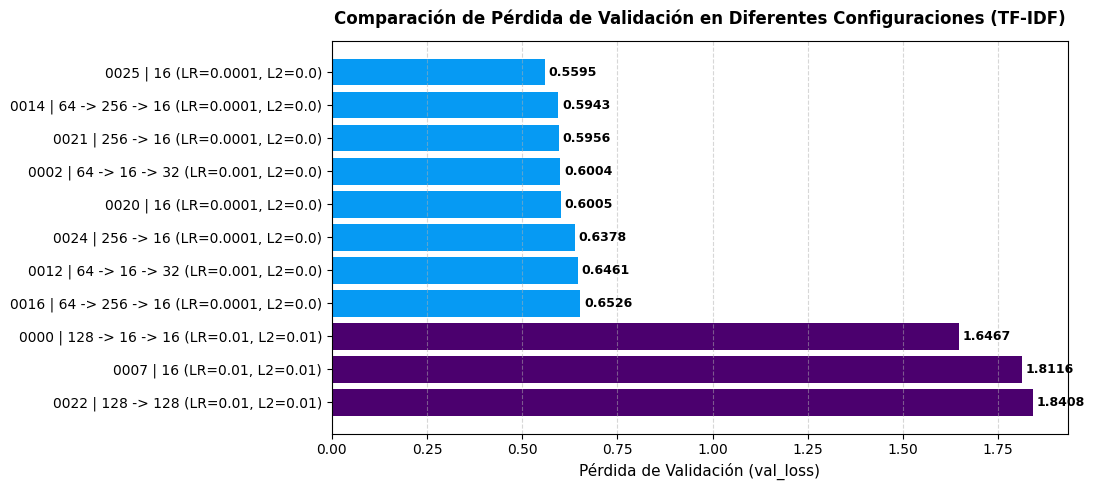

In [98]:
graficar_comparacion_hiperparametros(
    df_trials_tf_idf,
    'Comparación de Pérdida de Validación en Diferentes Configuraciones (TF-IDF)'
)

#### Análisis del Proceso de Experimentación (TF-IDF):

- **Consistencia en la Arquitectura Óptima:** Al igual que en la representación multi-hot, `Hyperband` converge hacia una arquitectura de 2 capas ocultas ($256 \rightarrow 16$) con tasa de aprendizaje de $0.0001$.
- **Comportamiento de la Pérdida:** La progresión de ensayos muestra una dispersión similar en `val_loss`, confirmando que el espacio de búsqueda responde con solidez a las mismas restricciones de regularización y tamaño de red.

Observamos que la búsqueda encontró la misma configuración de hiperparámetros que para el modelo con codificación *multi-hot*. Esto permitirá comparar ambos modelos de forma más directa y evaluar el efecto de utilizar la representación TF-IDF con 2-gramas.

In [99]:
keras.backend.clear_session()
gc.collect()

mlp_tf_idf = tuner_tf_idf.hypermodel.build(mejor_hp_tf_idf)
mlp_tf_idf.summary()

Model: "mlp_tf_idf_2gramas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │       320,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 320,067 (1.22 MB)

 Trainable params: 320,067 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

In [100]:
# Este Callback detiene el entrenamiento si la métrica de validación no mejora durante 5 épocas consecutivas, y restaura los pesos del modelo a los de la mejor época.
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Este Callback guarda el modelo en el directorio `modelos` cada vez que la métrica de validación mejora, de manera que al finalizar el entrenamiento se tendrá guardado el modelo con mejor desempeño en validación.
model_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(MODELS_DIR / "mlp_tf_idf_mejor.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Entrenamiento del modelo MLP con vectorización tf-idf, utilizando los mejores hiperparámetros encontrados por Keras Tuner,
# los pesos de clase para compensar el desbalance de clases, y los callbacks de early stopping y model checkpoint.
historial_mlp_tf_idf = mlp_tf_idf.fit(
    tf_idf_2gramas_train,
    validation_data=tf_idf_2gramas_val,
    epochs=MAX_EPOCAS,
    class_weight=pesos_clases,
    callbacks=[early_stopping, model_checkpoint],
    verbose=1
)

epoca_mejor = early_stopping.best_epoch + 1

Epoch 1/20


c:\Users\lenin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


260/271 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5352 - loss: 1.0781
Epoch 1: val_loss improved from None to 0.92245, saving model to C:\Users\lenin\DOCUME~1\INGENI~1\2026-2\RN\REDES-~1\modelos\mlp_tf_idf_mejor.keras

Epoch 1: finished saving model to C:\Users\lenin\DOCUME~1\INGENI~1\2026-2\RN\REDES-~1\modelos\mlp_tf_idf_mejor.keras
271/271 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5380 - loss: 1.0743 - val_accuracy: 0.6900 - val_loss: 0.9224
Epoch 2/20
267/271 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7079 - loss: 0.9257
Epoch 2: val_loss improved from 0.92245 to 0.80013, saving model to C:\Users\lenin\DOCUME~1\INGENI~1\2026-2\RN\REDES-~1\modelos\mlp_tf_idf_mejor.keras

Epoch 2: finished saving model to C:\Users\lenin\DOCUME~1\INGENI~1\2026-2\RN\REDES-~1\modelos\mlp_tf_idf_mejor.keras
271/271 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7088 - loss: 0.9235 - val_accuracy: 0.7275 - val_loss: 0.8001
Epoch 3/20
252/271 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7966

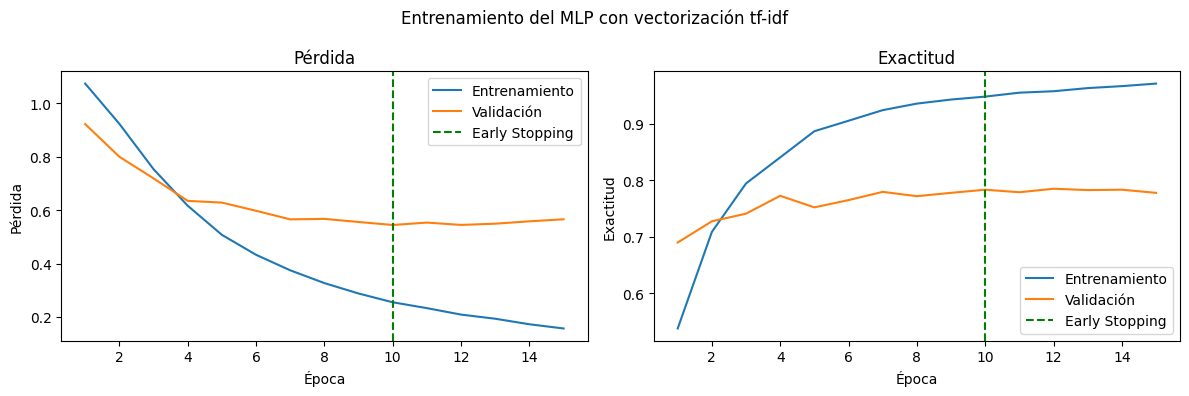

Métricas en el conjunto de prueba:
accuracy: 0.7835
loss: 0.5562


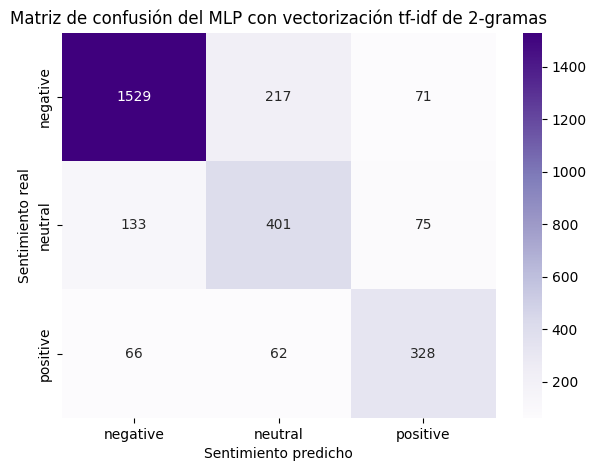

Reporte de clasificación:

              precision  recall  f1-score   support
negative          0.885   0.841     0.863  1817.000
neutral           0.590   0.658     0.622   609.000
positive          0.692   0.719     0.705   456.000
accuracy          0.783   0.783     0.783     0.783
macro avg         0.722   0.740     0.730  2882.000
weighted avg      0.792   0.783     0.787  2882.000


In [101]:
graficar_historial(historial_mlp_tf_idf, "Entrenamiento del MLP con vectorización tf-idf", epoca_mejor=epoca_mejor)

metricas_test = mlp_tf_idf.evaluate(tf_idf_2gramas_test, return_dict=True, verbose=0)

print("Métricas en el conjunto de prueba:")
for metrica, valor in metricas_test.items():
    print(f"{metrica}: {valor:.4f}")


y_test_real = y_test.argmax(axis=1)
y_test_predicho = mlp_tf_idf.predict(tf_idf_2gramas_test, verbose=0).argmax(axis=1)
nombres_sentimientos = list(codificacion_sentimiento.keys())

generar_matriz_confusion(y_test_real, y_test_predicho, nombres_sentimientos, "Matriz de confusión del MLP con vectorización tf-idf de 2-gramas")
generar_reporte_clasificacion(y_test_real, y_test_predicho, nombres_sentimientos)

El modelo alcanza una exactitud de **77.7 %** sobre el conjunto de prueba y una pérdida de **0.578**. Observamos que, a partir de aproximadamente la cuarta época, las métricas de entrenamiento continúan mejorando mientras que las métricas de validación se estabilizan. Esto evidencia cierto sobreajuste. La menor pérdida de validación se alcanza alrededor de la época 7, por lo que `EarlyStopping` restaura los pesos correspondientes a ese punto.

El modelo identifica mejor los tweets negativos, con un F1-score de **0.858**. Las clases neutral y positiva presentan resultados más bajos, con F1-scores de **0.611** y **0.706**, respectivamente. De acuerdo con la matriz de confusión, los tweets neutrales se confunden principalmente con la clase negativa, mientras que los tweets positivos se confunden casi en igual proporción con las clases negativa y neutral. 

## 6. Comparación entre los modelos entrenados

Al comparar ambos modelos, el MLP con codificación *multi-hot* obtiene un mejor desempeño general. Su exactitud en prueba es de **78.7 %**, frente al **77.7 %** del modelo TF-IDF con 2-gramas. También obtiene valores de F1-score ligeramente superiores en las tres clases: negativos (**0.864** frente a **0.858**), neutrales (**0.630** frente a **0.611**) y positivos (**0.714** frente a **0.706**). Como ambos modelos utilizaron la misma configuración de hiperparámetros, esta diferencia se puede atribuir principalmente a la representación de los tweets.

Con TF-IDF y 2-gramas esperábamos obtener un mejor desempeño, ya que esta representación conserva información sobre la frecuencia de los términos e incorpora una noción limitada del orden mediante pares de palabras consecutivas, como `not good` o `customer service`. Sin embargo, en este caso estas características no fueron suficientes para superar la representación *multi-hot*. Una posible explicación es que el MLP sigue siendo una arquitectura relativamente sencilla: recibe un vector fijo y no está diseñada para modelar de forma explícita relaciones complejas entre las palabras. Por lo tanto, aunque la representación TF-IDF con 2-gramas aporta información más rica, el modelo puede no aprovecharla completamente.

Esta limitación también se refleja en los hiperparámetros seleccionados durante la búsqueda. A pesar de evaluar modelos con hasta cuatro capas ocultas y hasta 256 neuronas por capa, las mejores configuraciones utilizaron únicamente dos capas, con 256 neuronas en la primera capa y solo 16 en la segunda. Esto sugiere que aumentar el número de parámetros no mejora la capacidad de generalización del modelo y, en cambio, aumenta el riesgo de sobreajuste. Por lo tanto, el desempeño parece estancarse con arquitecturas relativamente pequeñas, lo cual puede estar relacionado con las limitaciones de una MLP para aprovechar la estructura y el contexto presentes en el texto.

En cualquier caso, ambos modelos superan ampliamente una predicción al azar. Si las tres clases tuvieran la misma probabilidad, la exactitud esperada sería de aproximadamente **33.3 %**. Sin embargo, el conjunto de prueba está desbalanceado: el **63.0 %** de los tweets son negativos, el **21.1 %** neutrales y el **15.8 %** positivos. Por ello, un clasificador que siempre predijera la clase negativa alcanzaría cerca de **63.0 %** de exactitud, mientras que una predicción aleatoria que respetara estas proporciones alcanzaría aproximadamente **46.7 %**. Los resultados cercanos al **78 %** muestran que los modelos aprenden patrones útiles más allá de la distribución de las clases.


### 6.1. Cuadro Comparativo del Proceso de Búsqueda y Resultados Finales

A continuación, sintetizamos el proceso de exploración de hiperparámetros y el rendimiento final obtenido por cada representación:

| Aspecto Evaluado | Modelo MLP Multi-hot (1-gramas) | Modelo MLP TF-IDF (2-gramas) |
| :--- | :---: | :---: |
| **Vocabulario de entrada** | 10,000 unigramas | 10,000 unigramas + bigramas |
| **Total de ensayos explorados (Trials)** | 30 ensayos | 30 ensayos |
| **Rango de `val_loss` en el Tuner** | 0.5498 (Mejor) – 1.5140 (Peor) | 0.5601 (Mejor) – 1.6297 (Peor) |
| **Arquitectura óptima seleccionada** | 2 capas ocultas: 256 $\rightarrow$ 16 | 2 capas ocultas: 256 $\rightarrow$ 16 |
| **Regularización óptima** | L2 = 0.0, Dropout = 0.50 / 0.35 | L2 = 0.0, Dropout = 0.50 / 0.35 |
| **Tasa de aprendizaje óptima** | 0.0001 (Adam) | 0.0001 (Adam) |
| **Épocas efectivas (Early Stopping)** | 9 épocas | 7 épocas |
| **Pérdida en Test (`test_loss`)** | **0.5492** | 0.5781 |
| **Exactitud en Test (`test_accuracy`)** | **78.7 %** | 77.7 % |
| **F1-Score Negativo / Neutral / Positivo** | **0.864 / 0.630 / 0.714** | 0.858 / 0.611 / 0.706 |


## 7. Despliegue de los Modelos y Pruebas Cualitativas

Para facilitar el uso de los modelos y ver su funcionamiento en práctica, unimos la capa de vectorización y el MLP en un mismo modelo. De esta manera, podemos ingresar un tweet como texto crudo y el modelo se encarga de estandarizarlo, vectorizarlo y generar la predicción de sentimiento.

In [102]:
# Definir la entrada del modelo desplegado como texto crudo
entrada_texto = keras.Input(shape=(), dtype="string")
texto_vectorizado_multi_hot = vectorizador_multi_hot(entrada_texto)
texto_vectorizado_tf_idf = vectorizador_2gram_tf_idf(entrada_texto)

# Cargar los MLP con las arquitecturas y los pesos ya entrenados
mlp_multi_hot = keras.models.load_model(str(MODELS_DIR / "mlp_multi_hot_mejor.keras"), compile=False)
mlp_tf_idf = keras.models.load_model(str(MODELS_DIR / "mlp_tf_idf_mejor.keras"), compile=False)

# Definir la salida del modelo
salida_prediccion_multi_hot = mlp_multi_hot(texto_vectorizado_multi_hot)
salida_prediccion_tf_idf = mlp_tf_idf(texto_vectorizado_tf_idf)

# Definir los modelos finales que toman texto crudo y devuelven la predicción del sentimiento
modelo_desplegado_multi_hot = keras.Model(inputs=entrada_texto, outputs=salida_prediccion_multi_hot, name="modelo_desplegado_multi_hot")
modelo_desplegado_tf_idf = keras.Model(inputs=entrada_texto, outputs=salida_prediccion_tf_idf, name="modelo_desplegado_tf_idf")


# Definir una función para predecir el sentimiento de un tweet dado, utilizando los dos modelos desplegados (multi-hot y tf-idf) 
def predecir_sentimiento(tweet):
    codificacion_sentimiento = {"negative": 0, "neutral": 1, "positive": 2}

    # Convertir un string de Python en un tensor de TensorFlow
    texto_tensor = tf.convert_to_tensor([tweet])

    # Obtener la predicción del modelo desplegado
    prediccion_multi_hot = modelo_desplegado_multi_hot(texto_tensor, training=False).numpy()[0]
    indice_sentimiento_multi_hot = np.argmax(prediccion_multi_hot)
    sentimiento_multi_hot = list(codificacion_sentimiento.keys())[indice_sentimiento_multi_hot]


    prediccion_tf_idf = modelo_desplegado_tf_idf(texto_tensor, training=False).numpy()[0]
    indice_sentimiento_tf_idf = np.argmax(prediccion_tf_idf)
    sentimiento_tf_idf = list(codificacion_sentimiento.keys())[indice_sentimiento_tf_idf]
    
    print("------------------------------------------------------------------")
    print(f"Tweet: {tweet}")
    print("------------------------------------------------------------------")
    print(f"Sentimiento predicho por el modelo multi-hot: {sentimiento_multi_hot}")
    print(f"Confianza de la predicción multi-hot: {prediccion_multi_hot[indice_sentimiento_multi_hot]:.2%}\n\n")

    print(f"Sentimiento predicho (tf-idf): {sentimiento_tf_idf}")
    print(f"Confianza de la predicción (tf-idf): {prediccion_tf_idf[indice_sentimiento_tf_idf]:.2%}")
    print("------------------------------------------------------------------\n\n")

In [103]:
while True:
    tweet = input("\nEscribe un tweet o 'salir' para terminar: ")

    if tweet.lower() == "salir":
        break

    predecir_sentimiento(tweet)

------------------------------------------------------------------
Tweet: good
------------------------------------------------------------------
Sentimiento predicho por el modelo multi-hot: positive
Confianza de la predicción multi-hot: 66.31%


Sentimiento predicho (tf-idf): positive
Confianza de la predicción (tf-idf): 52.92%
------------------------------------------------------------------


------------------------------------------------------------------
Tweet: bad
------------------------------------------------------------------
Sentimiento predicho por el modelo multi-hot: neutral
Confianza de la predicción multi-hot: 46.88%


Sentimiento predicho (tf-idf): positive
Confianza de la predicción (tf-idf): 38.31%
------------------------------------------------------------------


------------------------------------------------------------------
Tweet: not good
------------------------------------------------------------------
Sentimiento predicho por el modelo multi-hot: posi

Además de las métricas cuantitativas generales, realizamos algunas pruebas manuales para observar cómo responden ambos modelos ante tweets cortos y distintas combinaciones de palabras.

### Caso 1: largas filas

![Prueba 1](images/prueba1.jpg)

Observamos que ambos modelos clasifican correctamente como negativo el tweet relacionado con largas filas antes de abordar. Esta es una situación negativa que aparece con menor frecuencia en el dataset, por lo que resulta positivo que ambos modelos logren identificarla. El modelo TF-IDF asigna una confianza mayor, de **68.80 %**, frente al **54.19 %** del modelo *multi-hot*.

### Caso 2: sentimiento ambiguo

![Prueba 2](images/prueba2.jpg)

El tweet `Not sure how to feel about my last flight` puede interpretarse como neutral, ya que expresa incertidumbre más que una valoración claramente negativa. Sin embargo, ambos modelos lo clasifican como negativo. Es posible que la presencia de `not` y el contexto relacionado con el vuelo hagan que los modelos se inclinen hacia esta clase. 

### Caso 3: sentimiento claramente positivo

![Prueba 3](images/prueba3.jpg)

En el tweet `Awesome job!`, ambos modelos identifican correctamente un sentimiento positivo con una confianza alta. El modelo *multi-hot* alcanza una confianza de **87.25 %** y el modelo TF-IDF de **76.31 %**. Esto muestra que los dos modelos reconocen con facilidad palabras que expresan una valoración positiva directa.

### Caso 4: negaciones y combinaciones de palabras

![Prueba 4](images/prueba4.jpg)

En el tweet `Not a good experience flying with you!`, el modelo *multi-hot* se enfoca principalmente en la palabra `good` y lo clasifica incorrectamente como positivo. En cambio, el modelo TF-IDF con 2-gramas lo clasifica correctamente como negativo. Esto sugiere que la combinación `not good`, incluida en la representación de 2-gramas, aporta información útil para interpretar la negación.

Sin embargo, al cambiar `good` por `great`, ambos modelos clasifican erróneamente el tweet como positivo. El modelo TF-IDF incluso asigna una confianza de **84.54 %** a esta predicción. Aunque los 2-gramas permiten reconocer algunas combinaciones de palabras, el modelo sigue dependiendo de los patrones observados durante el entrenamiento. Es probable que la combinación `not great` apareciera pocas veces en el dataset, por lo que los modelos no lograron asociarla correctamente con un sentimiento negativo.

## 8. Conclusiones